<div style="border-top:5px solid #173c63; padding:20px 0 15px 0; max-width:950px">
  <div style="color:#687e96;letter-spacing:0.13em;font-size:12px;font-weight:700">DIGITAL COMMUNICATIONS · CHAPTER 3 · REPRODUCIBLE NOTEBOOK</div>
  <h1 style="margin:10px 0 10px 0;font-size:31px">3.6.4 Examples Revisited</h1>
  <div style="font-size:19px;color:#396087">Symbol-Spaced &amp; Fractionally Spaced MMSE/ZF-DFE · PAM &amp; QAM</div>
  <div style="font-size:13px;color:#657385;margin-top:13px">Mathematical derivations · Canonical spectral factorization · Python reference model · Verification</div>
</div>

> **Abstract.** This notebook reproduces **Example 3.6.1 (real-valued two-tap PAM)** and **Example 3.6.2 (complex-valued three-tap QAM)** from Cioffi, *Digital Communications*, §3.6.4. For each example, we derive the channel energy, matched-filter autocorrelation, regularized spectrum, minimum-phase canonical factors, MMSE/ZF feedforward and feedback filters, and biased/unbiased detection SNRs. We first validate the textbook symbol-spaced models, then extend both examples to a four-branch **polyphase fractionally spaced MMSE-DFE / ZF-DFE**, including biased/unbiased feedback, frequency-domain identities, finite-length residuals, and Monte Carlo verification.

**Presentation style:** The chapter outline, mathematical exposition, figures, and executable code follow the technical-article presentation style of [A Fix for Softmax and Cross-Entropy](https://jonbarron.info/softmaxfix/); the DFE mathematics and numerical examples come from Cioffi §3.6.4 and are **unrelated to the research claims of the Softmax article**.

**Source:** J. M. Cioffi, *Digital Communications*, [Chapter 3](https://cioffi-group.stanford.edu/doc/book/chap3.pdf), §§3.6.1–3.6.4. Notebook conventions: 2-space indentation, approximately 120-column source lines, section-based Markdown, and in-place executable outputs.

## Contents

1. [Notation and normalization](#1-notation-and-normalization)
2. [Setup and reference-model interface](#2-setup-and-reference-model-interface)
3. [Example 3.6.1 — PAM-DFE](#3-example-361--pam-dfe)
4. [Example 3.6.2 — QAM-DFE](#4-example-362--qam-dfe)
5. [Whitening and bias-removal identities](#5-whitening-and-bias-removal-identities)
6. [Monte Carlo: correct feedback versus decision-directed](#6-monte-carlo-correct-feedback-versus-decision-directed)
7. [Finite feedforward approximation](#7-finite-feedforward-approximation)
8. [Comparative results and conclusions](#8-comparative-results-and-conclusions)

---
9. [Polyphase FS-DFE: sampled channel and noise model](#9-polyphase-fs-dfe-sampled-channel-and-noise-model)
10. [PAM: MMSEFSDFE and ZFFSDFE](#10-pam-mmsefsdfe-and-zffsdfe)
11. [QAM: MMSEFSDFE and ZFFSDFE](#11-qam-mmsefsdfe-and-zffsdfe)
12. [Polyphase filter identities and error whitening](#12-polyphase-filter-identities-and-error-whitening)
13. [High-rate Monte Carlo and finite FIR effects](#13-high-rate-monte-carlo-and-finite-fir-effects)
14. [Unified results and reproducibility](#14-unified-results-and-reproducibility)


## 1. Notation and normalization

To prevent confusion among different SNR definitions, filter coefficients, and noise variances, we preserve the textbook notation and do not introduce shorthand for frequency averages or SNR quantities.

| Quantity | Definition | Meaning |
|:--|:--|:--|
| $D$ | $z^{-1}$ | Delay operator for one symbol period |
| $T$ | $1$ | Symbol period, normalized to unity in this notebook |
| $\bar E_x$ | $1$ (per real dimension) | PAM has $\mathbb E[x_k^2]=1$; QAM has $\mathbb E[|x_k|^2]=2$ |
| $Q(D)$ | $\sum_m q_mD^m$ | Normalized matched-filter autocorrelation, with $q_0=1$ |
| $\|h\|^2$ | $\sum_m |h_m|^2$ | channel pulse energy |
| $N_0/2$ | $\bar E_x\|h\|^2/SNR_{\rm MFB}$ | Noise parameter per real dimension |
| $G(D),\gamma_0$ | $Q+1/SNR_{\rm MFB}=\gamma_0 GG^\sharp$ | MMSE canonical factors |
| $P_c(D),\eta_0$ | $Q=\eta_0P_cP_c^\sharp$ | ZF canonical factors |

**Complex conjugation:** We use $F^\sharp(D)\equiv F^*(D^{-*})$ as a convenient notation for the *paraconjugate*. This notation is introduced for explanation in this notebook; it is not an additional symbol defined by Cioffi. For

$$F(D)=f_0+f_1D+f_2D^2,\qquad F^\sharp(D)=f_0^*+f_1^*D^{-1}+f_2^*D^{-2}.$$

Matched-filter output model:

$$
Y(D)=\|h\|Q(D)X(D)+N(D),\qquad
\bar R_{nn}(D)=\frac{N_0}{2}Q(D),\qquad
SNR_{\rm MFB}=\frac{\bar E_x\|h\|^2}{N_0/2}.
$$

**Two DFE realizations:**

$$
\begin{aligned}
\text{MMSE: }&\; W(D)=\frac{1}{\|h\|\gamma_0G^\sharp(D)},\quad
B(D)=G(D),\quad\alpha=1-\frac{1}{\gamma_0SNR_{\rm MFB}},\\[3pt]
\text{ZF: }&\;W(D)=\frac{1}{\|h\|\eta_0P_c^\sharp(D)},\quad
B(D)=P_c(D),\quad\alpha=1.
\end{aligned}
$$

**The physical feedback filter is always $1-B(D)$, not $B(D)$ itself.** For MMSE-DFE, the biased decision input is $Z'(D)$. The unbiased output $Z'_U(D)=Z'(D)/\alpha$ can be passed to a slicer using the original constellation.

## 2. Setup and reference-model interface

This notebook imports the existing `MMSEDFE` and `ZFDFE` implementations from `adsp.equalization.canonical_dfe`; **it does not reimplement spectral factorization inside the notebook**. As in `09_fse_passband_nyquist_inband.ipynb`, the setup searches upward from the working directory for the repository root containing `adsp`.

- In the repository: place the notebook under `notebooks/` and ensure `adsp/equalization/canonical_dfe.py` is installed.
- In the standalone bundle: `adsp/` contains the required reference-model modules, so the notebook can run without additional project files.
- `n_taps` specifies a finite truncation of the ideal anticausal feedforward response; it is **not** the optimal finite-length FIR solution of Chapter 3.7.

**Extension (Sections 9–14):** `MMSEFSDFE` and `ZFFSDFE` perform polyphase feedforward filtering
at $T/4$ input sampling and symbol-rate decision feedback. The oversampled root-raised-cosine
pulse used to demonstrate their realizations is an **explicit modeling extension** of the
sinc-basis textbook examples, not an additional example claimed to appear in Cioffi §3.6.4.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

project_root = next(
  (path for path in [Path.cwd(), *Path.cwd().parents]
   if (path / "adsp" / "equalization" / "canonical_dfe.py").is_file()),
  None,
)
if project_root is None:
  raise FileNotFoundError("Cannot locate adsp/equalization/canonical_dfe.py from the notebook directory.")
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp.equalization.canonical_dfe import MMSEDFE, ZFDFE
from adsp.equalization.fse_dfe import MMSEFSDFE, ZFFSDFE
from adsp.equalization.pulses import sampledPulse, sampleChannelOutput

SNR_MFB = 10.0                   # 10 dB, linear power ratio
SYMBOL_ENERGY_PER_REAL = 1.0    # E_x in Cioffi's convention
N_FFT = 32768
N_FF = 160
RNG_SEED = 3642026

plt.rcParams.update({
  "figure.figsize": (9.0, 3.6),
  "figure.dpi": 105,
  "axes.grid": True,
  "grid.alpha": 0.23,
  "axes.spines.top": False,
  "axes.spines.right": False,
  "font.size": 10,
})
print("Project root:", project_root)
print(f"SNR_MFB = {SNR_MFB:.6f} (linear) = {10 * np.log10(SNR_MFB):.1f} dB")

Project root: /pysim
SNR_MFB = 10.000000 (linear) = 10.0 dB


In [2]:
def complexText(value: complex, digits: int = 8) -> str:
  """Readable complex coefficients for printed tables."""
  value = complex(value)
  if abs(value.imag) < 1e-12:
    return f"{value.real:.{digits}f}"
  return f"{value.real:.{digits}f} {value.imag:+.{digits}f}j"


def coefficientTable(indices, values, label="Coefficient") -> pd.DataFrame:
  return pd.DataFrame({
    "Lag / degree": np.asarray(indices, dtype=int),
    label: [complexText(value) for value in values],
  })


def fftOfIndexedTaps(taps, indices, n_fft: int) -> np.ndarray:
  """Evaluate sum_m taps[m] exp(-j 2*pi*k*m/N) on a unit-circle FFT grid."""
  periodic = np.zeros(n_fft, dtype=np.complex128)
  np.add.at(periodic, np.mod(np.asarray(indices, dtype=int), n_fft), taps)
  return np.fft.fft(periodic)


def buildDfePair(channel, constellation):
  args = dict(snr_mfb=SNR_MFB, n_taps=N_FF, n_fft=N_FFT, constellation=constellation)
  return MMSEDFE.fromChannel(channel, **args), ZFDFE.fromChannel(channel, **args)


def checkCanonical(model) -> float:
  """Independent reconstruction using the explicitly stored polynomial taps."""
  canonical = fftOfIndexedTaps(
    model.canonical_factor, np.arange(len(model.canonical_factor)), model.n_fft,
  )
  regularization = 1.0 / model.snr_mfb if model.criterion == "mmse" else 0.0
  residual = model._q_bins + regularization - model.factor_scale * abs(canonical)**2
  return float(np.max(abs(residual)))


def positiveDb(value: float) -> float:
  return float(10.0 * np.log10(value))

## 3. Example 3.6.1 — PAM-DFE

### 3.1 Channel response and autocorrelation — Eq. (3.270)

The textbook considers the following real-valued two-tap PAM channel:

$$H(\omega)=\sqrt T\left(1+0.9e^{j\omega T}\right),\qquad |\omega|\le\frac{\pi}{T}.$$

Because reversing the entire channel in time leaves its magnitude spectrum unchanged, the numerical model uses the corresponding sampled coefficients $h=[1,\;0.9]$. The channel energy is:

$$
\|h\|^2=|1|^2+|0.9|^2=1+0.81=\boxed{1.81}.
$$

With a matched-filter bound of $10\,\mathrm{dB}$, the noise parameter is:

$$
\frac{N_0}{2}=\frac{\bar E_x\|h\|^2}{SNR_{\rm MFB}}
=\frac{1\times1.81}{10}=\boxed{0.181}.
$$

The autocorrelation coefficients are $r_{hh}[0]=1.81$ and $r_{hh}[1]=r_{hh}[-1]=0.9$. Consequently,

$$
\begin{aligned}
Q(D)&=\frac{0.9D^{-1}+1.81+0.9D}{1.81}\\
&=\boxed{1+\frac{0.9}{1.81}(D+D^{-1})}.
\end{aligned}
$$

On the unit circle, with $D=e^{-j\omega T}$:

$$
Q(e^{-j\omega T})=\frac{1.81+1.8\cos(\omega T)}{1.81},\qquad
Q(e^{-j\pi})=\frac{0.01}{1.81}.
$$

The deep spectral notch near the Nyquist frequency causes substantial noise enhancement when the ZF-LE inverts the channel spectrum.

||h||^2 = 1.810000000, ||h|| = 1.345362405, N0/2 = 0.181000000


,Lag / degree,q[m]
0,-1,0.49723757
1,0,1.00000000
2,1,0.49723757


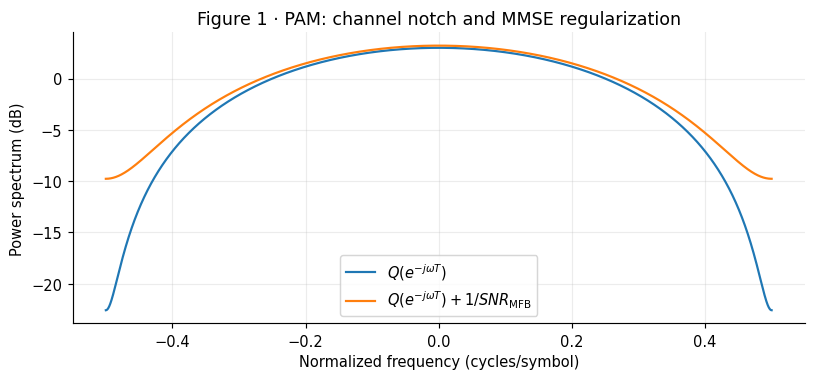

In [3]:
pam_h = np.array([1.0, 0.9], dtype=np.complex128)
pam_constellation = np.array([-1.0, 1.0], dtype=np.complex128)
pam_mmse, pam_zf = buildDfePair(pam_h, pam_constellation)
pam_energy = float(np.vdot(pam_h, pam_h).real)
pam_noise_var = SYMBOL_ENERGY_PER_REAL * pam_energy / SNR_MFB

print(f"||h||^2 = {pam_energy:.9f}, ||h|| = {np.sqrt(pam_energy):.9f}, N0/2 = {pam_noise_var:.9f}")
display(coefficientTable(pam_mmse.q_index, pam_mmse.q, "q[m]"))
assert np.isclose(pam_energy, 1.81)
assert np.allclose(pam_mmse.q, np.array([0.9, 1.81, 0.9]) / 1.81)

freq = np.fft.fftshift(np.fft.fftfreq(N_FFT))
pam_q_freq = np.fft.fftshift(pam_mmse._q_bins)
fig, ax = plt.subplots()
ax.plot(freq, 10 * np.log10(pam_q_freq), label=r"$Q(e^{-j\omega T})$")
ax.plot(freq, 10 * np.log10(pam_q_freq + 1 / SNR_MFB),
        label=r"$Q(e^{-j\omega T})+1/SNR_{\rm MFB}$")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Power spectrum (dB)",
       title="Figure 1 · PAM: channel notch and MMSE regularization")
ax.legend()
plt.show()

### 3.2 MMSE canonical factorization — Eq. (3.271)–(3.274)

The regularized spectrum explicitly includes $SNR_{\rm MFB}=10$:

$$
\begin{aligned}
Q(D)+\frac{1}{SNR_{\rm MFB}}
&=\frac{0.9D+1.81+0.9D^{-1}}{1.81}+0.1\\
&=\boxed{\frac{0.9D+1.991+0.9D^{-1}}{1.81}}.
\end{aligned}
$$

Since the autocorrelation has maximum positive lag $1$, choose a monic first-order factor $G(D)=1+g_1D$ and write

$$
Q(D)+\frac1{SNR_{\rm MFB}}=\gamma_0(1+g_1D)(1+g_1D^{-1}).
$$

Match the constant and $D^1$ coefficients:

$$
\gamma_0(1+g_1^2)=\frac{1.991}{1.81}=1.1,
\qquad \gamma_0 g_1=\frac{0.9}{1.81}.
$$

Eliminate $g_1$:

$$
\gamma_0^2-1.1\gamma_0+\left(\frac{0.9}{1.81}\right)^2=0,
\qquad
\gamma_0=\frac{1.1\pm\sqrt{1.1^2-4(0.9/1.81)^2}}{2}.
$$

Both algebraic solutions reconstruct the same power spectrum. **Select the solution satisfying $|g_1|<1$**: the zero of $G(z)=1+g_1z^{-1}$ is at $z=-g_1$, and the minimum-phase condition requires $|z|<1$.

In [4]:
pam_q1 = 0.9 / 1.81
pam_discriminant = 1.1**2 - 4 * pam_q1**2
pam_candidates = [(1.1 + np.sqrt(pam_discriminant)) / 2,
                  (1.1 - np.sqrt(pam_discriminant)) / 2]
pam_root_rows = []
for gamma0_candidate in pam_candidates:
  g1_candidate = pam_q1 / gamma0_candidate
  pam_root_rows.append({
    "gamma0 candidate": gamma0_candidate,
    "g1 candidate": g1_candidate,
    "zero z = -g1": -g1_candidate,
    "minimum-phase?": abs(g1_candidate) < 1.0,
  })
display(pd.DataFrame(pam_root_rows).round(9))

pam_gamma0_closed = next(value for value in pam_candidates if abs(pam_q1 / value) < 1.0)
pam_g1_closed = pam_q1 / pam_gamma0_closed
assert np.isclose(pam_mmse.gamma0, pam_gamma0_closed, atol=1e-10)
assert np.isclose(pam_mmse.canonical_factor[1], pam_g1_closed, atol=1e-10)
assert checkCanonical(pam_mmse) < 1e-10

print(f"Selected gamma_0 = {pam_mmse.gamma0:.10f}")
print(f"Selected G(D) = 1 + ({complexText(pam_mmse.canonical_factor[1], 10)}) D")
print(f"Maximum canonical reconstruction residual = {checkCanonical(pam_mmse):.3e}")

,gamma0 candidate,g1 candidate,zero z = -g1,minimum-phase?
0,0.785063,0.633373,-0.633373,True
1,0.314937,1.578850,-1.578850,False


Selected gamma_0 = 0.7850633955
Selected G(D) = 1 + (0.6333725046) D
Maximum canonical reconstruction residual = 1.776e-15


### 3.3 MMSE feedforward, feedback and unbiased SNR — Eq. (3.275)–(3.278)

Substitute $\gamma_0$ and $G(D)$ into the DFE filters derived by Cioffi:

$$
\begin{aligned}
W_{\rm MMSE-DFE}(D)
&=\frac{1}{\|h\|\gamma_0G^\sharp(D)}
=\frac{1}{\sqrt{1.81}\,(0.785063\ldots)(1+0.633372\ldots D^{-1})}\\[3pt]
&\approx\boxed{\frac{0.9469}{1+0.63337D^{-1}}},\\[3pt]
B_{\rm MMSE-DFE}(D)&=\boxed{1+0.63337D},\\
1-B_{\rm MMSE-DFE}(D)&=\boxed{-0.63337D}.
\end{aligned}
$$

Hence the actual feedback contribution is $-0.63337\hat x_{k-1}$. The ideal feedforward filter is anticausal:

$$
W(D)=\frac{1}{\|h\|\gamma_0}\left[1-g_1D^{-1}+g_1^2D^{-2}-\cdots\right].
$$

It requires future matched-filter samples. The $N_{\rm FF}=160$ implementation below is an **offline FIR truncation**, not a causal real-time realization.

The error variance, MSE-based SNR, desired-symbol bias, and **unbiased detection SNR** must be distinguished:

$$
\begin{aligned}
\sigma_{\rm MMSE-DFE}^2&=\frac{N_0/2}{\|h\|^2\gamma_0}
=\frac{0.181}{1.81\gamma_0}=\frac{0.1}{\gamma_0},\\
SNR_{\rm MMSE-DFE}&=\frac{\bar E_x}{\sigma_{\rm MMSE-DFE}^2}
=\gamma_0SNR_{\rm MFB},\\
\alpha&=1-\frac{1}{\gamma_0SNR_{\rm MFB}},\\
SNR_{\rm MMSE-DFE,U}&=\gamma_0SNR_{\rm MFB}-1.
\end{aligned}
$$

In [5]:
print(f"W_MMSE numerator = {1 / (pam_mmse.h_norm * pam_mmse.gamma0):.9f}")
print(f"G(D) coefficients  = {[complexText(c) for c in pam_mmse.canonical_factor]}")
print(f"1-G(D) coefficients= {[complexText(c) for c in pam_mmse.actualFeedbackTaps(unbiased=False)]}")
print(f"alpha               = {pam_mmse.alpha():.9f}")
print(f"G_U(D) coefficients= {[complexText(c) for c in pam_mmse.unbiasedFeedbackPolynomial()]}")
print(f"MMSE error variance = {pam_mmse.idealMse():.9f}")
print(f"Biased MSE SNR      = {pam_mmse.biasedSnr():.9f} (linear)")
print(f"Unbiased SNR        = {pam_mmse.unbiasedSnr():.9f} (linear) = "
      f"{positiveDb(pam_mmse.unbiasedSnr()):.6f} dB")
assert np.isclose(pam_mmse.unbiasedSnr(), pam_mmse.gamma0 * SNR_MFB - 1.0)

W_MMSE numerator = 0.946795062
G(D) coefficients  = ['1.00000000', '0.63337250']
1-G(D) coefficients= ['-0.63337250']
alpha               = 0.872621752
G_U(D) coefficients= ['1.00000000', '0.72582709']
MMSE error variance = 0.127378248
Biased MSE SNR      = 7.850633955 (linear)
Unbiased SNR        = 6.850633955 (linear) = 8.357308 dB


### 3.4 Zero-forcing canonical factorization — Eq. (3.264)–(3.269)

ZF-DFE **does not add the $1/SNR_{\rm MFB}$ regularization term**:

$$
Q(D)=\frac{(1+0.9D)(1+0.9D^{-1})}{1.81}
=\eta_0P_c(D)P_c^\sharp(D).
$$

The canonical factor and its scaling constant follow immediately:

$$
\boxed{P_c(D)=1+0.9D},\qquad
\boxed{\eta_0=\frac1{1+0.9^2}=\frac1{1.81}}.
$$

Its minimum-phase zero at $z=-0.9$ lies inside the unit circle. Therefore,

$$
\begin{aligned}
W_{\rm ZF-DFE}(D)
&=\frac1{\|h\|\eta_0P_c^\sharp(D)}
=\boxed{\frac{\sqrt{1.81}}{1+0.9D^{-1}}},\\
B_{\rm ZF-DFE}(D)&=1+0.9D,\qquad 1-B_{\rm ZF-DFE}(D)=-0.9D.
\end{aligned}
$$

Under correct past decisions, $Z'=X+N'$. Therefore, **ZF-DFE does not require the MMSE bias-removal multiplier**:

$$
\begin{aligned}
\sigma_{\rm ZF-DFE}^2&=\frac{N_0/2}{\|h\|^2\eta_0}
=\frac{0.181}{1.81(1/1.81)}=0.181,\\
SNR_{\rm ZF-DFE}&=\eta_0SNR_{\rm MFB}=\frac{10}{1.81}.
\end{aligned}
$$

In [6]:
print(f"P_c(D) = {pam_zf.canonical_factor}")
print(f"eta_0 = {pam_zf.eta0:.10f}, expected 1/1.81 = {1 / 1.81:.10f}")
print(f"W_ZF numerator = {1 / (pam_zf.h_norm * pam_zf.eta0):.9f}")
print(f"Actual feedback = {[complexText(v) for v in pam_zf.actualFeedbackTaps()]}")
print(f"ZF output noise = {pam_zf.idealOutputNoiseVariance():.9f}")
print(f"ZF SNR = {pam_zf.unbiasedSnr():.9f} (linear) = {positiveDb(pam_zf.unbiasedSnr()):.6f} dB")
assert np.isclose(pam_zf.eta0, 1 / 1.81, atol=1e-10)
assert np.isclose(pam_zf.alpha(), 1.0)
assert checkCanonical(pam_zf) < 1e-10

P_c(D) = [1. +0.000000e+00j 0.9-9.980444e-17j]
eta_0 = 0.5524861878, expected 1/1.81 = 0.5524861878
W_ZF numerator = 1.345362405
Actual feedback = ['-0.90000000']
ZF output noise = 0.181000000
ZF SNR = 5.524861878 (linear) = 7.423214 dB


### 3.5 PAM filter frequency responses

Compare the two feedforward filters for the same channel:

$$
\begin{aligned}
W_{\rm MMSE-DFE}(D)&=\frac{1}{\|h\|\gamma_0G^\sharp(D)},\\
W_{\rm ZF-DFE}(D)&=\frac{1}{\|h\|\eta_0P_c^\sharp(D)}.
\end{aligned}
$$

Because ZF-DFE has no regularization, it generally requires greater feedforward gain near a deep channel spectral notch and can be more difficult to approximate with a finite-length FIR.

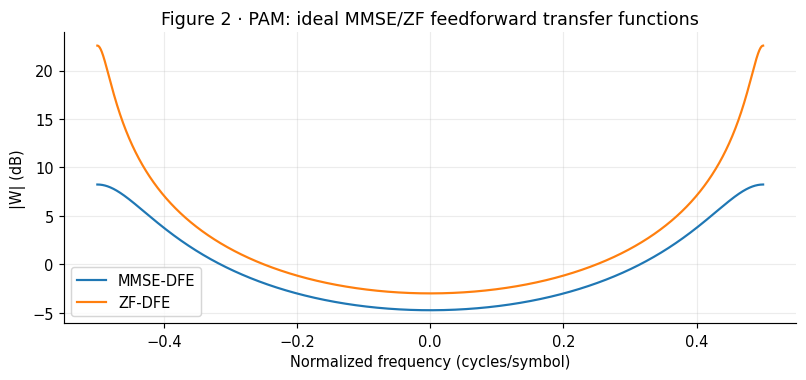

In [7]:
fig, ax = plt.subplots()
for label, equalizer in (("MMSE-DFE", pam_mmse), ("ZF-DFE", pam_zf)):
  omega, response = equalizer.frequencyResponse()
  ax.plot(omega / (2 * np.pi), 20 * np.log10(abs(response)), label=label)
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="|W| (dB)",
       title="Figure 2 · PAM: ideal MMSE/ZF feedforward transfer functions")
ax.legend()
plt.show()

## 4. Example 3.6.2 — QAM-DFE

### 4.1 Complex three-tap channel — Eq. (3.279)

Cioffi's complex-baseband QAM channel, with $T=1$, is

$$
\boxed{h_0=-\frac12,\quad h_1=1+\frac j4,\quad h_2=-\frac j2}.
$$

Channel energy:

$$
\begin{aligned}
\|h\|^2
&=\left|-\frac12\right|^2+\left|1+\frac j4\right|^2+\left|-\frac j2\right|^2\\
&=\frac14+\left(1+\frac1{16}\right)+\frac14
=\boxed{1.5625}.
\end{aligned}
$$

**Per-real-dimension convention:** QAM symbols are chosen from $\{\pm1\pm j\}$, so $\mathbb E[|x_k|^2]=2$, while each real I/Q dimension has $\bar E_x=1$. With $SNR_{\rm MFB}=10$:

$$\frac{N_0}{2}=\frac{1\times1.5625}{10}=\boxed{0.15625}.$$

The lag-$1$ and lag-$2$ complex autocorrelation coefficients must use the proper conjugates:

$$
\begin{aligned}
r_{hh}[0]&=|h_0|^2+|h_1|^2+|h_2|^2=1.5625,\\
r_{hh}[1]&=h_1h_0^*+h_2h_1^*=-0.625(1+j),\\
r_{hh}[2]&=h_2h_0^*=+0.25j,\\
r_{hh}[-1]&=r_{hh}[1]^*=-0.625(1-j),\\
r_{hh}[-2]&=r_{hh}[2]^*=-0.25j.
\end{aligned}
$$

Therefore:

$$
\boxed{
Q(D)=\frac{-0.25jD^{-2}-0.625(1-j)D^{-1}+1.5625
-0.625(1+j)D+0.25jD^2}{1.5625}
}.
$$

Equivalently:

$$Q(D)=1-0.4(1+j)D-0.4(1-j)D^{-1}+0.16jD^2-0.16jD^{-2}.$$

||h||^2 = 1.562500000, ||h|| = 1.250000000, N0/2 = 0.156250000


,Lag / degree,complex q[m]
0,-2,0.00000000 -0.16000000j
1,-1,-0.40000000 +0.40000000j
2,0,1.00000000
3,1,-0.40000000 -0.40000000j
4,2,0.00000000 +0.16000000j


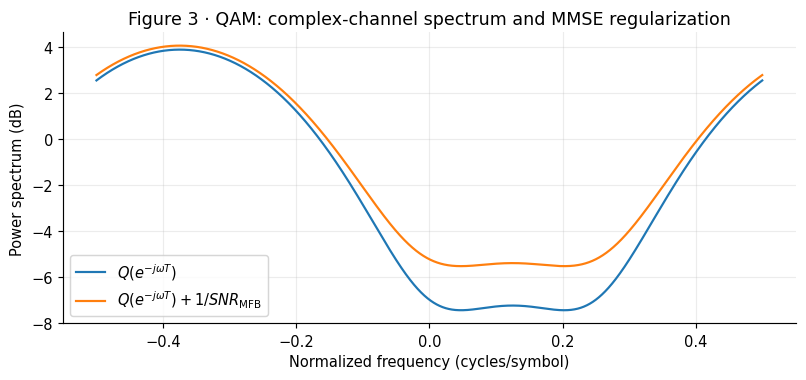

In [8]:
qam_h = np.array([-0.5, 1.0 + 0.25j, -0.5j], dtype=np.complex128)
qam_constellation = np.array([-1-1j, -1+1j, 1-1j, 1+1j], dtype=np.complex128)
qam_mmse, qam_zf = buildDfePair(qam_h, qam_constellation)
qam_energy = float(np.vdot(qam_h, qam_h).real)
qam_noise_var = SYMBOL_ENERGY_PER_REAL * qam_energy / SNR_MFB

print(f"||h||^2 = {qam_energy:.9f}, ||h|| = {np.sqrt(qam_energy):.9f}, N0/2 = {qam_noise_var:.9f}")
display(coefficientTable(qam_mmse.q_index, qam_mmse.q, "complex q[m]"))
assert np.isclose(qam_energy, 1.5625)
assert np.allclose(qam_mmse.q, np.conj(qam_mmse.q[::-1]), atol=1e-12)
assert np.isclose(qam_mmse.q[qam_mmse.q_index == 1][0], -0.4 - 0.4j)
assert np.isclose(qam_mmse.q[qam_mmse.q_index == 2][0], +0.16j)

qam_q_freq = np.fft.fftshift(qam_mmse._q_bins)
fig, ax = plt.subplots()
ax.plot(freq, 10 * np.log10(qam_q_freq), label=r"$Q(e^{-j\omega T})$")
ax.plot(freq, 10 * np.log10(qam_q_freq + 1 / SNR_MFB),
        label=r"$Q(e^{-j\omega T})+1/SNR_{\rm MFB}$")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Power spectrum (dB)",
       title="Figure 3 · QAM: complex-channel spectrum and MMSE regularization")
ax.legend()
plt.show()

### 4.2 MMSE spectral factor and conjugate-reciprocal roots — Eq. (3.280)–(3.283)

First add $1/SNR_{\rm MFB}=0.1$ to the constant term:

$$
\begin{aligned}
Q(D)+\frac1{SNR_{\rm MFB}}=
&-0.16jD^{-2}-0.4(1-j)D^{-1}\\
&+1.1-0.4(1+j)D+0.16jD^2.
\end{aligned}
$$

Let

$$
G(D)=1+g_1D+g_2D^2,\qquad
Q(D)+\frac1{SNR_{\rm MFB}}=\gamma_0G(D)G^\sharp(D).
$$

Coefficient matching gives:

$$
\begin{aligned}
1.1&=\gamma_0(1+|g_1|^2+|g_2|^2),\\
-0.4(1+j)&=\gamma_0(g_1+g_2g_1^*),\\
0.16j&=\gamma_0 g_2.
\end{aligned}
$$

The notebook does not hard-code the complex roots as predefined constants. `MMSEDFE.fromChannel` uses **complex-cepstrum spectral factorization**, and we independently verify that both zeros of $G(z)=z^2+g_1z+g_2$ satisfy $|z|<1$:

$$
\boxed{G(D)\approx1-0.4226005(1+j)D+0.2034277jD^2},\qquad
\boxed{\gamma_0\approx0.7865203}.
$$

On the unit circle, $G^\sharp(D)=1+g_1^*D^{-1}+g_2^*D^{-2}$; **complex conjugation must not be omitted**.

In [9]:
qam_g = qam_mmse.canonical_factor
qam_g_roots_z = np.roots(qam_g)      # roots of z^2 + g1*z + g2
qam_g_roots_d = np.roots(qam_g[::-1])

display(pd.DataFrame({
  "z-plane zero": [complexText(z, 9) for z in qam_g_roots_z],
  "|z|": np.abs(qam_g_roots_z),
  "D-plane root": [complexText(d, 9) for d in qam_g_roots_d],
  "minimum-phase?": np.abs(qam_g_roots_z) < 1,
}).round(9))

print(f"gamma_0 = {qam_mmse.gamma0:.10f}")
print("G(D) coefficients =", [complexText(c, 10) for c in qam_g])
print(f"Coefficient match, lag 0: {qam_mmse.gamma0 * np.sum(abs(qam_g)**2):.10f} (expected 1.1)")
print(f"Coefficient match, lag 1: {complexText(qam_mmse.gamma0 * (qam_g[1] + qam_g[2] * qam_g[1].conjugate()))}")
print(f"Coefficient match, lag 2: {complexText(qam_mmse.gamma0 * qam_g[2])}")
print(f"Max spectral reconstruction difference = {checkCanonical(qam_mmse):.3e}")
assert np.all(np.abs(qam_g_roots_z) < 1.0)
assert checkCanonical(qam_mmse) < 1e-10
assert np.isclose(qam_mmse.gamma0 * qam_g[2], 0.16j, atol=1e-9)

,z-plane zero,|z|,D-plane root,minimum-phase?
0,0.450185246 -0.027584709j,0.45103,-0.135599593 -2.212999056j,True
1,-0.027584709 +0.450185246j,0.45103,2.212999056 +0.135599593j,True


gamma_0 = 0.7865203315
G(D) coefficients = ['1.0000000000', '-0.4226005366 -0.4226005366j', '0.0000000000 +0.2034276720j']
Coefficient match, lag 0: 1.1000000000 (expected 1.1)
Coefficient match, lag 1: -0.40000000 -0.40000000j
Coefficient match, lag 2: 0.00000000 +0.16000000j
Max spectral reconstruction difference = 2.665e-15


### 4.3 MMSE feedforward, feedback, bias and SNR — Eq. (3.282)–(3.285)

Substitute the spectral factor into the MMSE-DFE design equations:

$$
\begin{aligned}
B_{\rm MMSE-DFE}(D)&=G(D)
\approx1-0.4226005(1+j)D+0.2034277jD^2,\\
1-B_{\rm MMSE-DFE}(D)&\approx0.4226005(1+j)D-0.2034277jD^2,\\
W_{\rm MMSE-DFE}(D)&=\frac{1}{1.25\gamma_0G^\sharp(D)}\\
&\approx\frac{1.01716}{1-0.4226005(1-j)D^{-1}-0.2034277jD^{-2}}.
\end{aligned}
$$

The receiver output under ideal correct feedback is therefore

$$
z'_k=z_k+0.4226005(1+j)\hat x_{k-1}-0.2034277j\hat x_{k-2}.
$$

Its theoretical MSE and unbiased SNR are:

$$
\boxed{\sigma_{\rm MMSE-DFE}^2=\frac{0.15625}{1.5625\gamma_0}=\frac{0.1}{\gamma_0}},
\quad
\boxed{SNR_{\rm MMSE-DFE,U}=\gamma_0\,10-1}.
$$

**QAM normalization:** Divide the simulated $|x_k-z'_k|^2$ by 2 when comparing with the theoretical MSE expressed per real dimension.

In [10]:
print(f"MMSE W(D) numerator = {1 / (qam_mmse.h_norm * qam_mmse.gamma0):.9f}")
print("MMSE B(D) polynomial=", [complexText(c) for c in qam_mmse.feedback_polynomial])
print("MMSE actual feedback=", [complexText(c) for c in qam_mmse.actualFeedbackTaps(unbiased=False)])
print(f"alpha = {qam_mmse.alpha():.9f}")
print("Unbiased feedback G_U=", [complexText(c) for c in qam_mmse.unbiasedFeedbackPolynomial()])
print(f"MMSE MSE per real dimension = {qam_mmse.idealMse():.9f}")
print(f"Unbiased SNR = {qam_mmse.unbiasedSnr():.9f} = {positiveDb(qam_mmse.unbiasedSnr()):.6f} dB")
assert np.isclose(qam_mmse.unbiasedSnr(), qam_mmse.gamma0 * SNR_MFB - 1.0)

MMSE W(D) numerator = 1.017138360
MMSE B(D) polynomial= ['1.00000000', '-0.42260054 -0.42260054j', '0.00000000 +0.20342767j']
MMSE actual feedback= ['0.42260054 +0.42260054j', '-0.00000000 -0.20342767j']
alpha = 0.872857705
Unbiased feedback G_U= ['1.00000000', '-0.48415742 -0.48415742j', '0.00000000 +0.23305938j']
MMSE MSE per real dimension = 0.127142295
Unbiased SNR = 6.865203315 = 8.366534 dB


### 4.4 ZF factorization — Eq. (3.286)–(3.291)

ZF-DFE factorizes the unregularized $Q(D)$ and selects the minimum-phase factor with two zeros:

$$
\boxed{P_c(D)=(1-0.5D)(1-0.5jD)=1-0.5(1+j)D+0.25jD^2}.
$$

The two $z$-plane zeros are at $z=0.5$ and $z=0.5j$. Since $q_0=1$:

$$
1=\eta_0\bigl(1+|-0.5(1+j)|^2+|0.25j|^2\bigr)
=\eta_0(1+0.5+0.0625),
$$

Consequently,

$$\boxed{\eta_0=\frac1{1.5625}=0.64}.$$

The ZF filters, output noise variance, and detection SNR are:

$$
\begin{aligned}
W_{\rm ZF-DFE}(D)
&=\frac1{1.25(0.64)P_c^\sharp(D)}
=\boxed{\frac{1.25}{1-0.5(1-j)D^{-1}-0.25jD^{-2}}},\\
1-B_{\rm ZF-DFE}(D)&=\boxed{0.5(1+j)D-0.25jD^2},\\
\sigma_{\rm ZF-DFE}^2&=\frac{0.15625}{1.5625(0.64)}=0.15625,\\
SNR_{\rm ZF-DFE}&=\frac{1}{0.15625}=6.4.
\end{aligned}
$$

In [11]:
print("ZF P_c(D) =", [complexText(c, 9) for c in qam_zf.canonical_factor])
print(f"ZF eta_0 = {qam_zf.eta0:.10f} (expected 0.6400000000)")
print(f"ZF W(D) numerator = {1 / (qam_zf.h_norm * qam_zf.eta0):.9f}")
print("ZF feedback 1-P_c =", [complexText(c) for c in qam_zf.actualFeedbackTaps()])
print(f"ZF output noise variance = {qam_zf.idealOutputNoiseVariance():.9f}")
print(f"ZF SNR = {qam_zf.unbiasedSnr():.9f} = {positiveDb(qam_zf.unbiasedSnr()):.6f} dB")
assert np.allclose(qam_zf.canonical_factor, [1, -0.5-0.5j, 0.25j], atol=1e-9)
assert np.isclose(qam_zf.eta0, 0.64, atol=1e-10)
assert checkCanonical(qam_zf) < 1e-10

ZF P_c(D) = ['1.000000000', '-0.500000000 -0.500000000j', '-0.000000000 +0.250000000j']
ZF eta_0 = 0.6400000000 (expected 0.6400000000)
ZF W(D) numerator = 1.250000000
ZF feedback 1-P_c = ['0.50000000 +0.50000000j', '0.00000000 -0.25000000j']
ZF output noise variance = 0.156250000
ZF SNR = 6.400000000 = 8.061800 dB


### 4.5 QAM frequency-domain comparison

MMSE regularization changes the canonical-factor coefficients, whereas ZF uses the minimum-phase spectral factorization of the original $Q(D)$. The following figure compares their feedforward-filter magnitude responses.

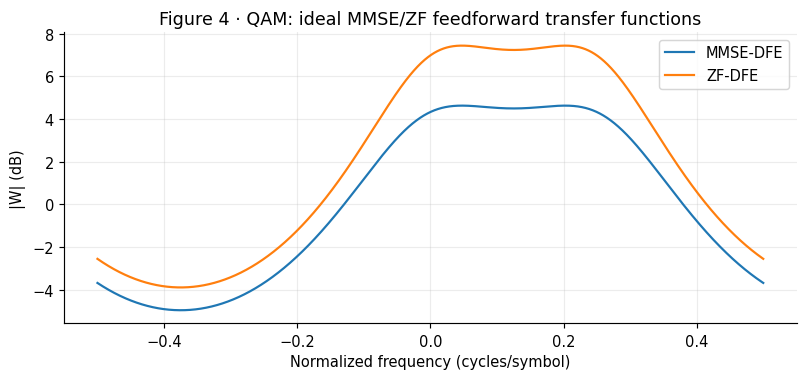

In [12]:
fig, ax = plt.subplots()
for label, equalizer in (("MMSE-DFE", qam_mmse), ("ZF-DFE", qam_zf)):
  omega, response = equalizer.frequencyResponse()
  ax.plot(omega / (2 * np.pi), 20 * np.log10(abs(response)), label=label)
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="|W| (dB)",
       title="Figure 4 · QAM: ideal MMSE/ZF feedforward transfer functions")
ax.legend()
plt.show()

## 5. Whitening and bias-removal identities

### 5.1 Why is the MMSE total estimation error white while the filtered noise need not be white?

For MMSE-DFE, define the correct-decision estimation error as

$$E(D)=B(D)X(D)-W(D)Y(D).$$

Substituting the matched-filter channel model $Y(D)=\|h\|Q(D)X(D)+N(D)$ gives

$$E(D)=\underbrace{\left[B(D)-\|h\|W(D)Q(D)\right]X(D)}_{\text{signal-dependent term}}
-\underbrace{W(D)N(D)}_{\text{filtered noise}}.$$

When symbols and noise are uncorrelated, the total error PSD is the sum of the two contributions:

$$
\bar R_{ee}(D)=
\bar E_x\left|B(D)-\|h\|W(D)Q(D)\right|^2
+\frac{N_0}{2}Q(D)|W(D)|^2
$$

(The magnitudes above are evaluated on the unit circle.) Canonical factorization guarantees

$$\boxed{\bar R_{ee}(D)=\frac{N_0/2}{\|h\|^2\gamma_0}},$$

which is constant. However, the filtered-noise contribution $\bar R_{n'n'}(D)$ generally varies with frequency. For ZF-DFE, the signal-dependent contribution vanishes under ideal conditions, so **the filtered noise itself is white**:

$$\boxed{\bar R_{n'n'}^{\rm ZF}(D)=\frac{N_0/2}{\|h\|^2\eta_0}}.$$

The following code reconstructs both PSDs directly from the ideal model frequency responses, checking each frequency bin rather than comparing only their integrated powers.

In [13]:
def idealErrorSpectra(equalizer, symbol_energy_per_real=1.0):
  q_freq = equalizer._q_bins
  w_freq = equalizer._w_bins
  b_freq = fftOfIndexedTaps(
    equalizer.canonical_factor, np.arange(len(equalizer.canonical_factor)), equalizer.n_fft,
  )
  noise_var = symbol_energy_per_real * equalizer.h_norm**2 / equalizer.snr_mfb
  signal_error = symbol_energy_per_real * abs(b_freq - equalizer.h_norm * w_freq * q_freq)**2
  filtered_noise = noise_var * q_freq * abs(w_freq)**2
  return signal_error, filtered_noise, signal_error + filtered_noise

for label, mmse, zf in (("PAM", pam_mmse, pam_zf), ("QAM", qam_mmse, qam_zf)):
  mmse_signal_psd, mmse_noise_psd, mmse_total_psd = idealErrorSpectra(mmse)
  zf_signal_psd, zf_noise_psd, zf_total_psd = idealErrorSpectra(zf)
  mmse_flatness = np.max(abs(mmse_total_psd - mmse.idealMse()))
  zf_flatness = np.max(abs(zf_noise_psd - zf.idealMse()))
  print(f"{label}: MMSE total-error PSD max residual = {mmse_flatness:.3e}; "
        f"ZF filtered-noise PSD max residual = {zf_flatness:.3e}")
  print(f"    MMSE filtered noise PSD range: {mmse_noise_psd.min():.7f} ... {mmse_noise_psd.max():.7f}")
  print(f"    ZF signal-dependent error PSD maximum: {zf_signal_psd.max():.3e}")
  assert mmse_flatness < 1e-9
  assert zf_flatness < 1e-9
  assert zf_signal_psd.max() < 1e-9

PAM: MMSE total-error PSD max residual = 5.551e-16; ZF filtered-noise PSD max residual = 5.829e-16
    MMSE filtered noise PSD range: 0.0066690 ... 0.1212966
    ZF signal-dependent error PSD maximum: 2.845e-29
QAM: MMSE total-error PSD max residual = 3.331e-16; ZF filtered-noise PSD max residual = 3.608e-16
    MMSE filtered noise PSD range: 0.0817343 ... 0.1221590
    ZF signal-dependent error PSD maximum: 4.006e-30


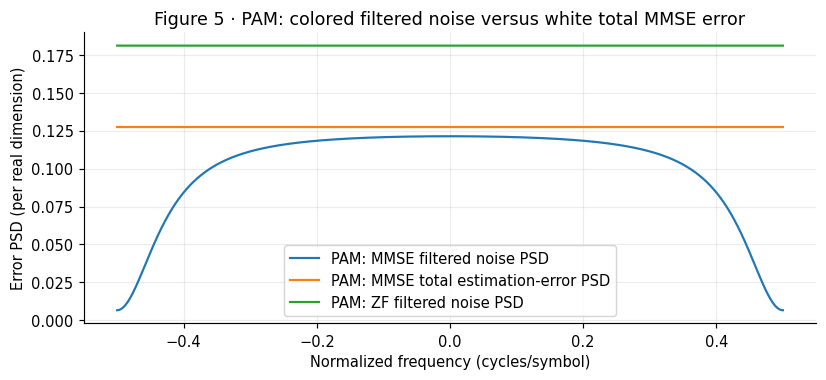

In [14]:
fig, ax = plt.subplots()
_, pam_noise, pam_total = idealErrorSpectra(pam_mmse)
_, pam_zf_noise, _ = idealErrorSpectra(pam_zf)
ax.plot(freq, np.fft.fftshift(pam_noise), label="PAM: MMSE filtered noise PSD")
ax.plot(freq, np.fft.fftshift(pam_total), label="PAM: MMSE total estimation-error PSD")
ax.plot(freq, np.fft.fftshift(pam_zf_noise), label="PAM: ZF filtered noise PSD")
ax.set(xlabel="Normalized frequency (cycles/symbol)", ylabel="Error PSD (per real dimension)",
       title="Figure 5 · PAM: colored filtered noise versus white total MMSE error")
ax.legend()
plt.show()

### 5.2 Biased and unbiased MMSE receiver structures

The unbiased scaling in Cioffi Figure 3.37 is

$$\alpha=1-\frac1{\gamma_0SNR_{\rm MFB}},\qquad
G_U(D)=1+\frac{G(D)-1}{\alpha}.$$

For any **identical feedback history**, even if some decisions are incorrect, the following identity holds:

$$
\begin{aligned}
Z'_U(D)&=\frac{Z(D)}{\alpha}+\left[1-G_U(D)\right]\hat X(D)\\
&=\frac{Z(D)+[1-G(D)]\hat X(D)}{\alpha}=\boxed{\frac{Z'(D)}{\alpha}}.
\end{aligned}
$$

The code uses `ideal_feedback=True` to ensure identical feedback histories in the biased and unbiased runs, then compares their outputs sample by sample. In ZF-DFE, $\alpha=1$, so the two forms coincide.

In [15]:
rng = np.random.default_rng(RNG_SEED)
for label, equalizer, constellation in (
  ("PAM", pam_mmse, pam_constellation),
  ("QAM", qam_mmse, qam_constellation),
):
  symbols = rng.choice(constellation, size=2048)
  received = equalizer.matchedFilterOutput(symbols)
  biased = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=False)
  unbiased = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=True)
  difference = np.max(abs(unbiased.decision_input - biased.decision_input / equalizer.alpha()))
  print(f"{label}: max |z'_U - z'/alpha| = {difference:.3e}, alpha = {equalizer.alpha():.9f}")
  assert difference < 1e-10

PAM: max |z'_U - z'/alpha| = 2.220e-16, alpha = 0.872621752
QAM: max |z'_U - z'/alpha| = 4.965e-16, alpha = 0.872857705


## 6. Monte Carlo: correct feedback versus decision-directed

To match the Cioffi matched-filter model, **independent white noise must not be added directly to the matched-filter samples**. Instead, the output noise must satisfy:

$$\bar R_{nn}(D)=\frac{N_0}{2}Q(D).$$

If $r_{hh}[m]$ is the channel autocorrelation, generate unit-variance white noise $v_k$ and form

$$n_k=\sqrt{\frac{N_0/2}{\|h\|^2}}\sum_mh_m v_{k-m}.$$

For QAM, the real and imaginary components of $v_k$ each have variance 1, so $\mathbb E[|v_k|^2]=2$. Divide the resulting complex MSE by 2 to recover the per-real-dimension convention.

Compare two feedback assumptions:

- **Correct-decision benchmark**:`ideal_feedback=True` uses the actual past transmitted symbols to validate the theoretical MSE (this is not a practical blind receiver).
- **Decision-directed**:Teacher forcing supplies correct symbols to the feedback history for the first 384 symbols; subsequent symbols use hard decisions. The filter **does not perform LMS/RLS adaptation**.

To avoid finite-record boundary transients from the noncausal feedforward filter, the first and last 384 symbols are excluded from statistics.

In [16]:
def randomSymbols(rng, constellation, n_symbols):
  return rng.choice(constellation, size=n_symbols).astype(np.complex128)


def matchedFilterNoise(rng, h, n_symbols, noise_var_per_real, complex_channel):
  """Synthesize matched-filter colored noise; QAM I/Q each has real variance noise_var_per_real."""
  white = rng.standard_normal(n_symbols + len(h) - 1)
  if complex_channel:
    white = white + 1j * rng.standard_normal(n_symbols + len(h) - 1)
  raw = np.convolve(white, h, mode="full")[:n_symbols]
  return raw * np.sqrt(noise_var_per_real / np.vdot(h, h).real)


def evaluateReceiver(equalizer, received, symbols, guard, real_dimensions):
  correct = equalizer.apply(received, known_symbols=symbols, ideal_feedback=True, unbiased=True)
  directed = equalizer.apply(received, known_symbols=symbols, training_samples=guard, unbiased=True)
  valid = slice(guard, len(symbols) - guard)
  return {
    "correct_feedback_mse": float(np.mean(abs(symbols[valid] - correct.decision_input[valid])**2)
                                  / real_dimensions),
    "decision_directed_mse": float(np.mean(abs(symbols[valid] - directed.decision_input[valid])**2)
                                    / real_dimensions),
    "correct_feedback_ser": float(np.mean(correct.decisions[valid] != symbols[valid])),
    "decision_directed_ser": float(np.mean(directed.decisions[valid] != symbols[valid])),
    "correct_output": correct,
    "directed_output": directed,
  }

In [17]:
N_SYMBOLS = 24000
GUARD = 384
simulation_rows = []
simulation_results = {}
rng = np.random.default_rng(RNG_SEED)

for label, h, constellation, mmse, zf, n_real in (
  ("PAM", pam_h, pam_constellation, pam_mmse, pam_zf, 1),
  ("QAM", qam_h, qam_constellation, qam_mmse, qam_zf, 2),
):
  symbols = randomSymbols(rng, constellation, N_SYMBOLS)
  noise_var = float(np.vdot(h, h).real / SNR_MFB)
  colored_noise = matchedFilterNoise(rng, h, N_SYMBOLS, noise_var, label == "QAM")
  received = mmse.matchedFilterOutput(symbols, noise=colored_noise)

  for criterion, equalizer in (("MMSE", mmse), ("ZF", zf)):
    metrics = evaluateReceiver(equalizer, received, symbols, GUARD, n_real)
    simulation_results[(label, criterion)] = metrics
    theoretical_unbiased_mse = SYMBOL_ENERGY_PER_REAL / equalizer.unbiasedSnr()
    simulation_rows.append({
      "Channel": label,
      "DFE": criterion,
      "Theoretical unbiased MSE": theoretical_unbiased_mse,
      "Correct-feedback MSE": metrics["correct_feedback_mse"],
      "Decision-directed MSE": metrics["decision_directed_mse"],
      "Correct-feedback SER": metrics["correct_feedback_ser"],
      "Decision-directed SER": metrics["decision_directed_ser"],
    })
    relative_difference = abs(metrics["correct_feedback_mse"] - theoretical_unbiased_mse)
    assert relative_difference / theoretical_unbiased_mse < 0.10

simulation_table = pd.DataFrame(simulation_rows)
display(simulation_table.round(6))
print(f"Evaluated {N_SYMBOLS - 2 * GUARD} central symbol decisions per channel/method.")

,Channel,DFE,Theoretical unbiased MSE,Correct-feedback MSE,Decision-directed MSE,Correct-feedback SER,Decision-directed SER
0,PAM,MMSE,0.145972,0.146503,0.171085,0.004950,0.013128
1,PAM,ZF,0.181000,0.182088,0.238513,0.009642,0.017949
2,QAM,MMSE,0.145662,0.146136,0.156622,0.008394,0.014162
3,QAM,ZF,0.156250,0.157258,0.175167,0.011751,0.018810


Evaluated 23232 central symbol decisions per channel/method.


### 6.1 How to interpret Monte Carlo MSE

The optimal MMSE error variance derived in §3.6 refers to the **biased estimation error**:

$$\sigma_{\rm MMSE-DFE}^2=\frac{\bar E_x}{\gamma_0SNR_{\rm MFB}}.$$

In this simulation, `decision_input` uses `unbiased=True`, so the relevant variance is instead

$$\boxed{\sigma_{\rm MMSE-DFE,U}^2=\frac{\bar E_x}{\gamma_0SNR_{\rm MFB}-1}}.$$

For ZF-DFE:

$$\boxed{\sigma_{\rm ZF-DFE}^2=\frac{\bar E_x}{\eta_0SNR_{\rm MFB}}}.$$

Accordingly, `Theoretical unbiased MSE` is computed as `1 / unbiasedSnr()`, not taken directly from the class method `idealMse()` (which returns the biased MSE for MMSE-DFE). With a sufficiently long finite feedforward filter and transient removal, the correct-feedback MSE should approach theory; decision-directed MSE may additionally suffer from **error propagation**.

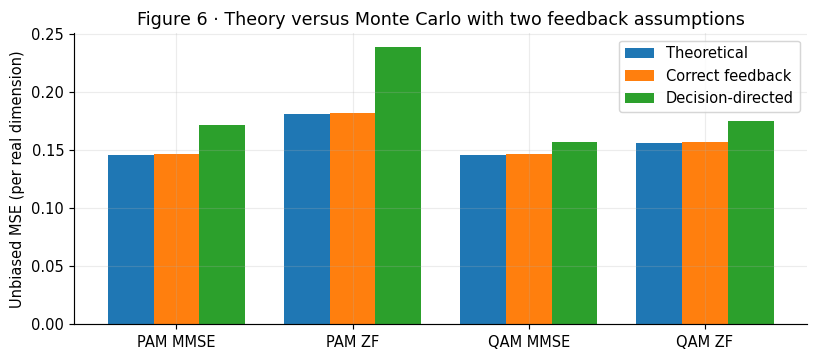

In [18]:
fig, ax = plt.subplots()
method_names = [f"{r['Channel']} {r['DFE']}" for r in simulation_rows]
positions = np.arange(len(method_names), dtype=float)
bar_width = 0.26
ax.bar(positions - bar_width, simulation_table["Theoretical unbiased MSE"],
       width=bar_width, label="Theoretical")
ax.bar(positions, simulation_table["Correct-feedback MSE"], width=bar_width, label="Correct feedback")
ax.bar(positions + bar_width, simulation_table["Decision-directed MSE"],
       width=bar_width, label="Decision-directed")
ax.set_xticks(positions, method_names)
ax.set(ylabel="Unbiased MSE (per real dimension)",
       title="Figure 6 · Theory versus Monte Carlo with two feedback assumptions")
ax.legend()
plt.show()

## 7. Finite feedforward approximation

The $W(D)$ response derived in Cioffi §3.6.4 generally has an **infinite anticausal tail**. The existing `canonical_dfe.py` samples the ideal frequency response $W(e^{-j\omega T})$ and extracts $N_{\rm FF}$ FIR taps:

$$W_{\rm finite}(D)=\sum_{m=1-N_{\rm FF}}^{0}w_mD^m.$$

Here we calculate the exact second-order MSE of the finite FIR approximation instead of relying on Monte Carlo sampling error. Under correct feedback:

$$
Z'(D)=\left[\|h\|W_{\rm finite}(D)Q(D)+1-B(D)\right]X(D)+W_{\rm finite}(D)N(D).
$$

When the unbiased output is defined as $Z'_U=Z'/\alpha$, the resulting error variance is

$$
\boxed{
\begin{aligned}
\sigma_{\rm finite,U}^2=
&\frac{\bar E_x}{2\pi}\int_{-\pi}^{\pi}
\left|1-\frac{\|h\|W_{\rm finite}(e^{-j\theta})Q(e^{-j\theta})+1-B(e^{-j\theta})}
{\alpha}\right|^2d\theta\\
&+\frac{N_0/2}{2\pi}\int_{-\pi}^{\pi}
Q(e^{-j\theta})\left|\frac{W_{\rm finite}(e^{-j\theta})}{\alpha}\right|^2d\theta.
\end{aligned}
}
$$

This measures the performance of an **ideal canonical factor combined with a truncated feedforward FIR**; it is not the jointly optimized finite FF/FB design of Chapter 3.7.

In [19]:
def finiteUnbiasedMse(equalizer):
  w_freq = fftOfIndexedTaps(equalizer.w, equalizer.w_index, equalizer.n_fft)
  b_freq = fftOfIndexedTaps(
    equalizer.feedback_polynomial,
    np.arange(len(equalizer.feedback_polynomial)),
    equalizer.n_fft,
  )
  alpha = equalizer.alpha()
  cascade = (equalizer.h_norm * w_freq * equalizer._q_bins + 1 - b_freq) / alpha
  noise_var = SYMBOL_ENERGY_PER_REAL * equalizer.h_norm**2 / equalizer.snr_mfb
  return float(np.mean(SYMBOL_ENERGY_PER_REAL * abs(1 - cascade)**2 +
                       noise_var * equalizer._q_bins * abs(w_freq / alpha)**2))

finite_rows = []
for label, h, constellation in (
  ("PAM", pam_h, pam_constellation),
  ("QAM", qam_h, qam_constellation),
):
  for taps in (8, 16, 32, 64, 128, N_FF):
    for cls, criterion in ((MMSEDFE, "MMSE"), (ZFDFE, "ZF")):
      equalizer = cls.fromChannel(h, snr_mfb=SNR_MFB, n_taps=taps,
                                  n_fft=N_FFT, constellation=constellation)
      finite_rows.append({
        "Channel": label,
        "DFE": criterion,
        "FF taps": taps,
        "Finite unbiased MSE": finiteUnbiasedMse(equalizer),
        "Ideal unbiased MSE": SYMBOL_ENERGY_PER_REAL / equalizer.unbiasedSnr(),
      })
finite_table = pd.DataFrame(finite_rows)
display(finite_table.pivot_table(index=["Channel", "DFE"], columns="FF taps",
                                 values="Finite unbiased MSE").round(6))

FF taps            8         16        32        64        128       160
Channel DFE                                                             
PAM     MMSE  0.147094  0.145973  0.145972  0.145972  0.145972  0.145972
        ZF    0.549936  0.249365  0.183347  0.181003  0.181000  0.181000
QAM     MMSE  0.145673  0.145662  0.145662  0.145662  0.145662  0.145662
        ZF    0.156276  0.156250  0.156250  0.156250  0.156250  0.156250

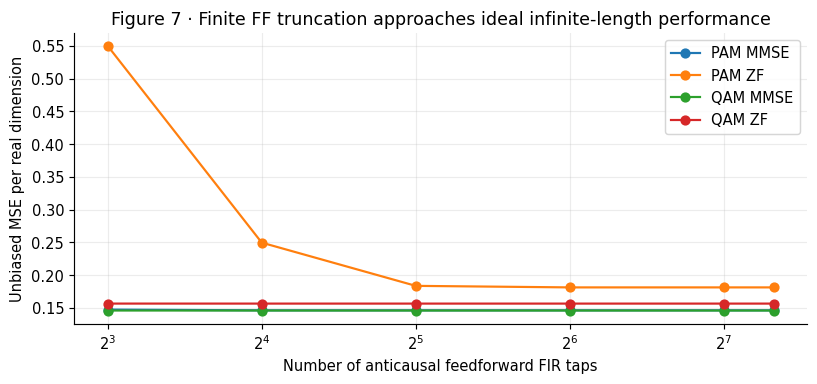

In [20]:
fig, ax = plt.subplots()
for channel_name in ("PAM", "QAM"):
  for criterion in ("MMSE", "ZF"):
    subset = finite_table[(finite_table["Channel"] == channel_name) &
                          (finite_table["DFE"] == criterion)].sort_values("FF taps")
    ax.plot(subset["FF taps"], subset["Finite unbiased MSE"], "o-",
            label=f"{channel_name} {criterion}")
ax.set(xlabel="Number of anticausal feedforward FIR taps", ylabel="Unbiased MSE per real dimension",
       title="Figure 7 · Finite FF truncation approaches ideal infinite-length performance")
ax.set_xscale("log", base=2)
ax.legend()
plt.show()

## 8. Comparative results and conclusions

### 8.1 Computing detection SNR directly from the three formulas

Continuing the comparison from §3.6.3, we retain the full frequency integrals instead of introducing a frequency-average shorthand:

$$
SNR_{\rm ZF-LE}=
\frac{SNR_{\rm MFB}}{\displaystyle\frac{T}{2\pi}
\int_{-\pi/T}^{\pi/T}\frac{1}{Q(e^{-j\omega T})}\,d\omega}.
$$

$$
SNR_{\rm ZF-DFE}=
SNR_{\rm MFB}\exp\left[\frac{T}{2\pi}
\int_{-\pi/T}^{\pi/T}\ln Q(e^{-j\omega T})\,d\omega\right].
$$

$$
SNR_{\rm MMSE-DFE,U}=
\exp\left[\frac{T}{2\pi}\int_{-\pi/T}^{\pi/T}
\ln\left(1+SNR_{\rm MFB}Q(e^{-j\omega T})\right)d\omega\right]-1.
$$

Under the ideal assumptions:

$$\boxed{SNR_{\rm ZF-LE}\le SNR_{\rm ZF-DFE}\le SNR_{\rm MMSE-DFE,U}\le SNR_{\rm MFB}}.$$

The code evaluates these three frequency-domain expressions by numerical quadrature on a dense frequency grid and compares them with the results returned by `MMSEDFE` and `ZFDFE`.

In [21]:
comparison_rows = []
for name, mmse, zf in (("PAM", pam_mmse, pam_zf), ("QAM", qam_mmse, qam_zf)):
  q_bins = mmse._q_bins
  snr_zf_le = SNR_MFB / float(np.mean(1.0 / q_bins))
  snr_zf_dfe_integral = SNR_MFB * float(np.exp(np.mean(np.log(q_bins))))
  snr_mmse_dfe_integral = float(np.exp(np.mean(np.log(1.0 + SNR_MFB * q_bins))) - 1.0)
  assert snr_zf_le <= snr_zf_dfe_integral + 1e-11
  assert snr_zf_dfe_integral <= snr_mmse_dfe_integral + 1e-11
  assert snr_mmse_dfe_integral <= SNR_MFB + 1e-11
  assert np.isclose(zf.unbiasedSnr(), snr_zf_dfe_integral, atol=1e-10)
  assert np.isclose(mmse.unbiasedSnr(), snr_mmse_dfe_integral, atol=1e-10)
  comparison_rows.append({
    "Channel": name,
    "ZF-LE (dB)": positiveDb(snr_zf_le),
    "ZF-DFE (dB)": positiveDb(snr_zf_dfe_integral),
    "MMSE-DFE,U (dB)": positiveDb(snr_mmse_dfe_integral),
    "MFB (dB)": positiveDb(SNR_MFB),
  })
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(6))

,Channel,ZF-LE (dB),ZF-DFE (dB),"MMSE-DFE,U (dB)",MFB (dB)
0,PAM,0.210750,7.423214,8.357308,10.0
1,QAM,6.106602,8.061800,8.366534,10.0


### 8.2 Reproducibility checks

All assertions pass, providing numerical checks of the following properties:

1. The PAM values $\gamma_0\approx0.785063$ and $\eta_0=1/1.81$, together with the roots used for the minimum-phase selection.
2. Hermitian symmetry of the complex QAM autocorrelation and $\eta_0=0.64$.
3. MMSE/ZF spectral reconstruction, including the complex $D^2$ coefficient.
4. Whiteness of the MMSE total-error PSD and of the ZF filtered-noise PSD.
5. Equivalence of MMSE biased/unbiased outputs under $Z'_U=Z'/\alpha$.
6. Consistency between Monte Carlo correct-feedback unbiased MSE and the Chapter 3.6 theoretical SNR.
7. The performance gap between finite anticausal feedforward approximations and ideal infinite-length feedforward filters.

**Implementation boundary:** The DFE assumes a known channel and uses an offline approximation of the noncausal feedforward response. It does not implement channel estimation, LMS/RLS coefficient updates, or a hardware decision delay. Incorrect feedback decisions may cause error propagation, reducing performance relative to the ideal SNR. Before targeting RTL, study the jointly optimal finite-length FF/FB design in Chapter 3.7.

**Original references:** Cioffi, *Digital Communications*, Chapter 3, §3.6.4, Examples Revisited. The accompanying `adsp/equalization/canonical_dfe.py` documents the reference-model API.

In [22]:
print("REPRODUCTION PASSED")
print("  PAM MMSE-DFE,U:  ", f"{positiveDb(pam_mmse.unbiasedSnr()):.6f} dB")
print("  PAM ZF-DFE:      ", f"{positiveDb(pam_zf.unbiasedSnr()):.6f} dB")
print("  QAM MMSE-DFE,U:  ", f"{positiveDb(qam_mmse.unbiasedSnr()):.6f} dB")
print("  QAM ZF-DFE:      ", f"{positiveDb(qam_zf.unbiasedSnr()):.6f} dB")
print(f"  Canonical reconstruction: {max(checkCanonical(eq) for eq in (pam_mmse,pam_zf,qam_mmse,qam_zf)):.3e}")
print("  Reference-model classes: adsp.equalization.canonical_dfe.MMSEDFE / ZFDFE")

REPRODUCTION PASSED
  PAM MMSE-DFE,U:   8.357308 dB
  PAM ZF-DFE:       7.423214 dB
  QAM MMSE-DFE,U:   8.366534 dB
  QAM ZF-DFE:       8.061800 dB
  Canonical reconstruction: 2.665e-15
  Reference-model classes: adsp.equalization.canonical_dfe.MMSEDFE / ZFDFE


## 9. Polyphase FS-DFE: sampled channel and noise model

**Scope and attribution.** Cioffi §3.6.4 analyzes symbol-spaced PAM and QAM DFEs. The extension below
uses the **fractionally spaced feedforward realization** discussed in §3.5.4 and the **MMSE/ZF
canonical factors** of §3.6. The sampling/pulse approximation, finite FIR truncation, and Monte
Carlo measurements are numerical implementation choices, **not** extra textbook formulas.

### 9.1 Four-branch high-rate channel

For $\ell=4$ samples per transmitted symbol, $T_s=T/4$. With high-rate pulse samples $g[n]$,
transmitted symbols $x[k]$, and high-rate receiver noise $v[n]$, model the anti-alias-filter output as

$$
\boxed{r[n]=\sum_k x[k]g[n-4k]+v[n],\qquad T_s=\frac{T}{4}.}
$$

The polyphase deinterleaver is **not four separate symbol-spaced samples of the original channel**;
each branch selects a different phase of the same high-rate stream:

$$
\begin{aligned}
y_0[k]&=r[4k], & h_0[m]&=g[4m],\\
y_1[k]&=r[4k-1], & h_1[m]&=g[4m-1],\\
y_2[k]&=r[4k-2], & h_2[m]&=g[4m-2],\\
y_3[k]&=r[4k-3], & h_3[m]&=g[4m-3].
\end{aligned}
$$

For each branch define $H_i(D)=\sum_m h_i[m]D^m$ and
$H_i^\sharp(D)=H_i^*(D^{-*})$. Here $D$ is a **symbol-period** delay inside the branch filters.
The feedforward output, before the symbol-rate feedback adder, is

$$
\boxed{
Z(D)=\sum_{i=0}^{3}W_i^{\rm FS}(D)Y_i(D),\qquad
z_k=\sum_{i=0}^{3}\sum_m w_i[m]r[4(k-m)-i].
}
$$

### 9.2 Normalization, matched-filter sufficient statistic, and $Q(D)$

The discrete-time approximation to the unit-normalized pulse energy is

$$
\boxed{\|h\|_{\rm FS}^2=\frac14\sum_n|g[n]|^2.}
$$

The equivalent matched-filter statistic and its normalized channel PSD follow directly:

$$
\begin{aligned}
Y_{\rm MF}(D)
&=\frac{1}{4\|h\|_{\rm FS}}\sum_{i=0}^{3}H_i^\sharp(D)Y_i(D),\\
Q_{\rm FS}(D)
&=\frac{1}{4\|h\|_{\rm FS}^2}\sum_{i=0}^{3}H_i^\sharp(D)H_i(D),\\
Y_{\rm MF}(D)&=\|h\|_{\rm FS}Q_{\rm FS}(D)X(D)+N_{\rm MF}(D).
\end{aligned}
$$

We use the same real-dimension conventions as the preceding textbook calculations. Let
$\bar E_x=1$ per real dimension, and set the independent high-rate noise in **each real dimension**
to variance $4(N_0/2)$. Thus

$$
\begin{aligned}
\bar R_{v_iv_j}(D)&=4\frac{N_0}{2}\,\delta_{ij},\\
\bar R_{N_{\rm MF}N_{\rm MF}}(D)&=\frac{N_0}{2}Q_{\rm FS}(D),\\
SNR_{\rm MFB}&=\frac{\bar E_x\|h\|_{\rm FS}^2}{N_0/2}=10.
\end{aligned}
$$

For complex QAM, $\mathbb E[|x_k|^2]=2\bar E_x$, and real and imaginary parts of $v[n]$
each have variance $4(N_0/2)$. All reported MSEs are **per real dimension**.

### 9.3 Canonical factorization and the actual feedforward branches

For the **MMSEFSDFE**,

$$
\begin{aligned}
Q_{\rm FS}(D)+\frac{1}{SNR_{\rm MFB}}
&=\gamma_{0,\rm FS}G_{\rm FS}(D)G_{\rm FS}^\sharp(D),\\
\boxed{W_{i,\rm MMSEFSDFE}(D)
=\frac{H_i^\sharp(D)}{4\|h\|_{\rm FS}^2\gamma_{0,\rm FS}G_{\rm FS}^\sharp(D)}},\\
\boxed{B_{\rm MMSEFSDFE}(D)=G_{\rm FS}(D)},\\
\alpha_{\rm FS}&=1-\frac{1}{\gamma_{0,\rm FS}SNR_{\rm MFB}},\\
G_{U,\rm FS}(D)&=1+\frac{G_{\rm FS}(D)-1}{\alpha_{\rm FS}},\\
SNR_{\rm MMSEFSDFE,U}&=\gamma_{0,\rm FS}SNR_{\rm MFB}-1.
\end{aligned}
$$

For the **ZFFSDFE**,

$$
\begin{aligned}
Q_{\rm FS}(D)
&=\eta_{0,\rm FS}P_{c,\rm FS}(D)P_{c,\rm FS}^\sharp(D),\\
\boxed{W_{i,\rm ZFFSDFE}(D)
=\frac{H_i^\sharp(D)}{4\|h\|_{\rm FS}^2\eta_{0,\rm FS}P_{c,\rm FS}^\sharp(D)}},\\
\boxed{B_{\rm ZFFSDFE}(D)=P_{c,\rm FS}(D)},\\
\alpha_{\rm ZF}&=1,\qquad
SNR_{\rm ZFFSDFE}=\eta_{0,\rm FS}SNR_{\rm MFB}.
\end{aligned}
$$

**Actual decision feedback** always uses $1-B(D)$ (strictly causal), not $B(D)$ itself.
The FF is implemented as finite centered FIR per branch, while the FFT-grid expressions are
infinite-length design references. Neither approximation is the jointly optimal finite-length
FF/FB design of Chapter 3.7.

In [23]:
# T=1 is a normalized sampling convention. The finite RRC pulse makes a physically
# meaningful four-phase receiver without changing the tapped PAM/QAM channel.
FS_OVERSAMPLING = 4
FS_ROLLOFF = 0.35
FS_SPAN_SYMBOLS = 24
FS_FF_TAPS_PER_BRANCH = 161


def buildFsDfePair(channel, constellation):
  g_index, g = sampledPulse(
    channel, oversampling=FS_OVERSAMPLING,
    span_symbols=FS_SPAN_SYMBOLS, rolloff=FS_ROLLOFF,
  )
  pulse_energy = float(np.vdot(g, g).real / FS_OVERSAMPLING)
  noise_var_per_real = SYMBOL_ENERGY_PER_REAL * pulse_energy / SNR_MFB
  args = dict(
    oversampling=FS_OVERSAMPLING,
    symbol_energy=SYMBOL_ENERGY_PER_REAL,
    noise_var=noise_var_per_real,
    n_fft=N_FFT,
    n_taps=FS_FF_TAPS_PER_BRANCH,
    n_fb=len(channel) - 1,  # textbook order; finite pulse leaves small extra ISI
    constellation=constellation,
  )
  return (MMSEFSDFE.fromPulse(g_index, g, **args),
          ZFFSDFE.fromPulse(g_index, g, **args), g_index, g)


def fsFactorCheck(model):
  """Evaluate |Q+regularization-factor_scale*|G|^2| over all FFT bins."""
  regularization = 1.0 / model.snr_mfb if model.criterion == "mmse" else 0.0
  residual = (model.polyphaseQBins() + regularization
              - model.factor_scale * np.abs(model._g_bins)**2)
  return float(np.max(np.abs(residual)))


def fsSummary(name, fs_model, symbol_model):
  return {
    "Example": name,
    "Method": fs_model.__class__.__name__,
    "\u03b3\u2080 / \u03b7\u2080 (FS)": fs_model.factor_scale,
    "\u03b3\u2080 / \u03b7\u2080 (SS)": symbol_model.factor_scale,
    "\u03b1 (FS)": fs_model.alpha(),
    "SNR_FS (dB)": positiveDb(fs_model.unbiasedSnr()),
    "SNR_SS (dB)": positiveDb(symbol_model.unbiasedSnr()),
    "Difference (dB)": positiveDb(fs_model.unbiasedSnr() / symbol_model.unbiasedSnr()),
  }

print(f"Polyphase sampling: {FS_OVERSAMPLING} samples/symbol, T_s=T/{FS_OVERSAMPLING}")
print(f"Pulse: RRC(beta={FS_ROLLOFF}), span={FS_SPAN_SYMBOLS} symbols on each side")
print(f"Feedforward FIR length: {FS_FF_TAPS_PER_BRANCH} taps per phase")

Polyphase sampling: 4 samples/symbol, T_s=T/4
Pulse: RRC(beta=0.35), span=24 symbols on each side
Feedforward FIR length: 161 taps per phase


## 10. PAM: MMSEFSDFE and ZFFSDFE

### 10.1 Reuse the two-tap channel of Example 3.6.1

The **textbook** normalized matched-filter channel is

$$
Q_{\rm PAM}(D)=\frac{(1+0.9D)(1+0.9D^{-1})}{1.81},
\qquad \|h\|^2=1.81.
$$

The four-phase pulse generator uses the same taps $[1,0.9]$ convolved with a **finite-sample RRC
pulse**. For an ideal energy-normalized Nyquist pulse with sufficient sampling, the four-phase
matched-filter construction reproduces the textbook $Q_{\rm PAM}(D)$. Since our RRC is truncated,
$Q_{\rm FS}(D)$ is **approximately** the textbook $Q(D)$, not literally identical.

The code prints $\|h\|_{\rm FS}^2$, zero-lag normalization, and the maximum FFT-grid spectrum
difference. Unlike a degenerate zero-stuffed channel, the constructed pulse has real energy
in all four branches.

In [24]:
pam_fs_mmse, pam_fs_zf, pam_g_index, pam_g = buildFsDfePair(pam_h, pam_constellation)
pam_fs_h2 = pam_fs_mmse.h_norm**2
pam_fs_q_error = float(np.max(np.abs(pam_fs_mmse._q_bins - pam_mmse._q_bins)))

print("PAM four-phase pulse energy =", f"{pam_fs_h2:.10f}")
print("Textbook PAM channel energy =", f"{np.vdot(pam_h, pam_h).real:.10f}")
print("Normalized q_FS[0]         =", complexText(pam_fs_mmse.q[pam_fs_mmse.q_zero_index]))
print("max |Q_FS - Q_textbook|    =", f"{pam_fs_q_error:.6e}")
print("Each branch energy:", [f"{np.vdot(branch, branch).real:.7f}" for branch in pam_fs_mmse.h_branch])

pam_fs_q_table = pd.DataFrame({
  "Symbol lag": list(range(-2, 3)),
  "Textbook Q(D)": [complexText(pam_mmse.q[pam_mmse.q_zero_index + i]) if abs(i) <= 1 else "0"
                     for i in range(-2, 3)],
  "4-phase Q_FS(D)": [complexText(pam_fs_mmse.q[pam_fs_mmse.q_zero_index + i])
                      for i in range(-2, 3)],
})
display(pam_fs_q_table)
assert np.isclose(pam_fs_mmse.q[pam_fs_mmse.q_zero_index], 1.0)
assert pam_fs_q_error < 0.002
assert all(np.vdot(hi, hi).real > 0.01 for hi in pam_fs_mmse.h_branch)

PAM four-phase pulse energy = 1.8099988692
Textbook PAM channel energy = 1.8100000000
Normalized q_FS[0]         = 1.00000000
max |Q_FS - Q_textbook|    = 2.609755e-04
Each branch energy: ['1.8562737', '1.8099988', '1.7637240', '1.8099989']


,Symbol lag,Textbook Q(D),4-phase Q_FS(D)
0,-2,0,0.00000042
1,-1,0.49723757,0.49723818
2,0,1.00000000,1.00000000
3,1,0.49723757,0.49723818
4,2,0,0.00000042


### 10.2 Recalculate the PAM canonical factors

For the **ideal** textbook PAM autocorrelation, coefficient matching from §3.6.4 gave

$$
\begin{aligned}
Q_{\rm PAM}(D)+\frac1{10}
&=0.7850634(1+0.6333725D)(1+0.6333725D^{-1}),\\
Q_{\rm PAM}(D)
&=\frac1{1.81}(1+0.9D)(1+0.9D^{-1}).
\end{aligned}
$$

Now repeat the canonical factorization on the actual *four-phase* $Q_{\rm FS}(D)$:

$$
\begin{aligned}
\gamma_{0,\rm FS}
&=\exp\left[\frac{T}{2\pi}\int_{-\pi/T}^{\pi/T}
\ln\left(Q_{\rm FS}(e^{-j\omega T})+\frac1{10}\right)d\omega\right],\\
\eta_{0,\rm FS}
&=\exp\left[\frac{T}{2\pi}\int_{-\pi/T}^{\pi/T}
\ln Q_{\rm FS}(e^{-j\omega T})\,d\omega\right].
\end{aligned}
$$

The code uses FFT quadrature and the **minimum-phase complex cepstrum**, as implemented in
`canonical_dfe.py`. For a truncated RRC, the full spectral factor may have many tiny coefficients.
The realized feedback polynomial uses the **one-tap feedback order** of the textbook example,
while the full canonical factor remains available for ideal spectrum calculations.

In [25]:
for criterion, fs_model, textbook_model in (
  ("MMSE", pam_fs_mmse, pam_mmse),
  ("ZF", pam_fs_zf, pam_zf),
):
  print(f"{criterion:4s}: scale_FS={fs_model.factor_scale:.10f}, "
        f"scale_textbook={textbook_model.factor_scale:.10f}, "
        f"alpha={fs_model.alpha():.10f}, "
        f"unbiased_SNR={positiveDb(fs_model.unbiasedSnr()):.6f} dB")
  print("        G_FS / P_c,FS (first coefficients):",
        [complexText(c, 9) for c in fs_model.canonical_factor[:3]])
  print("        actual feedback filter (1-B):",
        [complexText(c, 9) for c in fs_model.actualFeedbackTaps(unbiased=False)])
  print("        spectral factorization max error:", f"{fsFactorCheck(fs_model):.3e}")
  assert fsFactorCheck(fs_model) < 2e-12
  assert abs(positiveDb(fs_model.unbiasedSnr() / textbook_model.unbiasedSnr())) < 0.005

pam_fs_comparison = pd.DataFrame([
  fsSummary("PAM", pam_fs_mmse, pam_mmse),
  fsSummary("PAM", pam_fs_zf, pam_zf),
])
display(pam_fs_comparison.round(8))

MMSE: scale_FS=0.7850630900, scale_textbook=0.7850633955, alpha=0.8726217023, unbiased_SNR=8.357306 dB
        G_FS / P_c,FS (first coefficients): ['1.000000000', '0.633372924', '0.000000959']
        actual feedback filter (1-B): ['-0.633372924']
        spectral factorization max error: 3.997e-15
ZF  : scale_FS=0.5524735106, scale_textbook=0.5524861878, alpha=1.0000000000, unbiased_SNR=7.423115 dB
        G_FS / P_c,FS (first coefficients): ['1.000000000', '0.900023058', '-0.000001434']
        actual feedback filter (1-B): ['-0.900023058']
        spectral factorization max error: 5.107e-15


,Example,Method,γ₀ / η₀ (FS),γ₀ / η₀ (SS),α (FS),SNR_FS (dB),SNR_SS (dB),Difference (dB)
0,PAM,MMSEFSDFE,0.785063,0.785063,0.872622,8.357306,8.357308,-0.000002
1,PAM,ZFFSDFE,0.552474,0.552486,1.000000,7.423115,7.423214,-0.000100


### 10.3 PAM: four explicit feedforward branch responses

For MMSE, each branch has an anticausal component inherited from
$G_{\rm FS}^\sharp(D)^{-1}$ and a matched-filter component $H_i^\sharp(D)$:

$$
\boxed{W_{i,\rm MMSEFSDFE}(D)=
\frac{H_i^\sharp(D)}{4\|h\|_{\rm FS}^2\gamma_{0,\rm FS}G_{\rm FS}^\sharp(D)},
\quad i=0,1,2,3.}
$$

For ZF use $\eta_{0,\rm FS}P_{c,\rm FS}^\sharp(D)$ in the denominator instead.
The time-domain implementation extracts **161 centered FIR taps per branch** of the ideal
frequency-domain response; this is not a jointly optimized finite MMSE/ZF FIR.

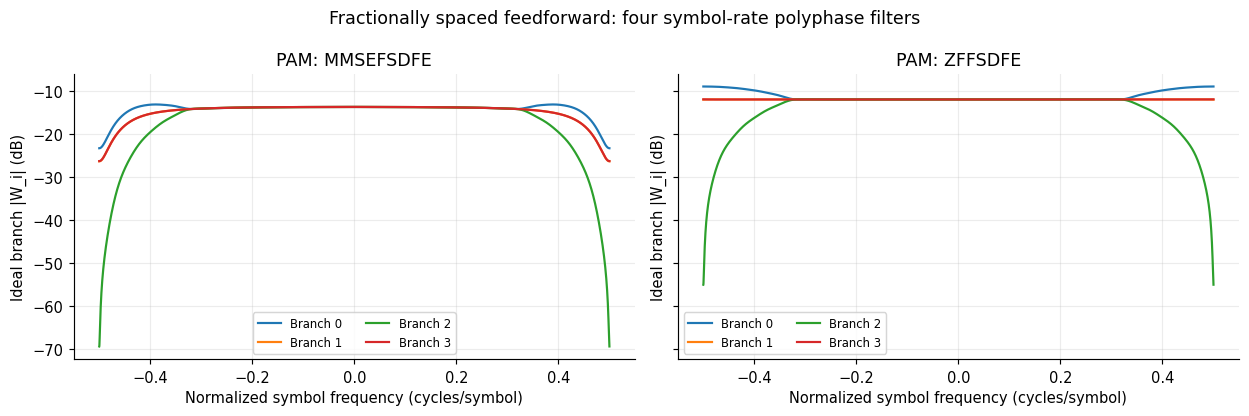

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True)
for ax, model, title in (
  (axes[0], pam_fs_mmse, "PAM: MMSEFSDFE"),
  (axes[1], pam_fs_zf, "PAM: ZFFSDFE"),
):
  freq = np.fft.fftshift(model._omega_bins) / (2 * np.pi)
  for branch in range(FS_OVERSAMPLING):
    magnitude = np.abs(np.fft.fftshift(model.w_branch_bins[branch]))
    ax.plot(freq, 20 * np.log10(np.maximum(magnitude, 1e-12)), label=f"Branch {branch}")
  ax.set(title=title, xlabel="Normalized symbol frequency (cycles/symbol)",
         ylabel="Ideal branch |W_i| (dB)")
  ax.legend(ncol=2, fontsize=8)
plt.suptitle("Fractionally spaced feedforward: four symbol-rate polyphase filters")
plt.tight_layout()
plt.show()

## 11. QAM: MMSEFSDFE and ZFFSDFE

### 11.1 Complex channel and paraconjugate polyphase autocorrelation

Cioffi's three-tap QAM channel remains

$$
\boxed{h_0=-\frac12,\qquad h_1=1+\frac j4,\qquad h_2=-\frac j2,\quad\|h\|^2=1.5625.}
$$

The symbol-spaced normalized autocorrelation in §3.6.4 is

$$
\begin{aligned}
Q_{\rm QAM}(D)
={}&1.0-0.4(1+j)D-0.4(1-j)D^{-1}
+0.16jD^2-0.16jD^{-2}.
\end{aligned}
$$

Construct each complex polyphase impulse response
$h_i[m]=\sum_{k=0}^{2}h_kp(m-i/4-k)$, using the same finite RRC sampling kernel $p(t)$.
The actual $Q_{\rm FS}$ must preserve **Hermitian symmetry**:

$$
q_{\rm FS}[-m]=q_{\rm FS}[m]^*,\qquad
Q_{\rm FS}(e^{-j\omega T})\in\mathbb R_{\ge0}.
$$

This test is especially useful because an incorrect complex conjugation can produce plausible
coefficient magnitudes but wrong equalizer phases and wrong feedback decisions.

In [27]:
qam_fs_mmse, qam_fs_zf, qam_g_index, qam_g = buildFsDfePair(qam_h, qam_constellation)
qam_fs_q_error = float(np.max(np.abs(qam_fs_mmse._q_bins - qam_mmse._q_bins)))
qam_fs_lags = np.arange(-2, 3)
qam_fs_q_table = pd.DataFrame({
  "Lag": qam_fs_lags,
  "Textbook Q(D)": [complexText(qam_mmse.q[qam_mmse.q_zero_index + int(lag)])
                     for lag in qam_fs_lags],
  "Polyphase Q_FS(D)": [complexText(qam_fs_mmse.q[qam_fs_mmse.q_zero_index + int(lag)])
                        for lag in qam_fs_lags],
})
display(qam_fs_q_table)
print(f"QAM polyphase channel energy: {qam_fs_mmse.h_norm**2:.9f}")
print(f"QAM textbook channel energy: {np.vdot(qam_h, qam_h).real:.9f}")
print(f"max|Q_FS-Q_textbook|: {qam_fs_q_error:.6e}")
print("max complex Hermitian mismatch:",
      float(np.max(np.abs(qam_fs_mmse.q - np.conj(qam_fs_mmse.q[::-1])))))
assert qam_fs_q_error < 0.002
assert np.allclose(qam_fs_mmse.q, np.conj(qam_fs_mmse.q[::-1]), atol=1e-12)

,Lag,Textbook Q(D),Polyphase Q_FS(D)
0,-2,0.00000000 -0.16000000j,0.00000098 -0.15999927j
1,-1,-0.40000000 +0.40000000j,-0.39999986 +0.39999959j
2,0,1.00000000,1.00000000
3,1,-0.40000000 -0.40000000j,-0.39999986 -0.39999959j
4,2,0.00000000 +0.16000000j,0.00000098 +0.15999927j


QAM polyphase channel energy: 1.562497659
QAM textbook channel energy: 1.562500000
max|Q_FS-Q_textbook|: 1.347612e-03
max complex Hermitian mismatch: 0.0


### 11.2 Compare complex canonical factors and feedback coefficients

The **textbook symbol-spaced results** are

$$
\begin{aligned}
G_{\rm QAM}(D)&=1-0.4226005(1+j)D+0.2034277jD^2,\\
P_{c,\rm QAM}(D)&=1-0.5(1+j)D+0.25jD^2,\\
\gamma_{0,\rm QAM}&\simeq0.7865203,\qquad\eta_{0,\rm QAM}=0.64.
\end{aligned}
$$

The **four-phase results** use the actual $Q_{\rm FS}(D)$ and retain **two** feedback taps to
match the textbook architecture. This is a deliberate finite-feedback approximation: a finite RRC
pulse introduces small longer-lag terms even though the ideal tapped-channel polynomial has order 2.

For the MMSE unbiased form the actual feedback transfer function is

$$
\boxed{1-G_{U,\rm FS}(D)
=-\frac{g_{1,\rm FS}}{\alpha_{\rm FS}}D
-\frac{g_{2,\rm FS}}{\alpha_{\rm FS}}D^2.}
$$

For ZF, since $\alpha=1$, the actual feedback is simply
$1-P_{c,\rm FS}(D)$ after the slicer.

In [28]:
for criterion, fs_model, textbook_model in (
  ("MMSE", qam_fs_mmse, qam_mmse),
  ("ZF", qam_fs_zf, qam_zf),
):
  print(f"{criterion:4s}: factor_FS={fs_model.factor_scale:.10f}, "
        f"factor_SS={textbook_model.factor_scale:.10f}, "
        f"alpha={fs_model.alpha():.9f}")
  display(pd.DataFrame({
    "Degree": np.arange(len(fs_model.feedback_polynomial)),
    "B_FS(D)": [complexText(c, 9) for c in fs_model.feedback_polynomial],
    "B_textbook(D)": [complexText(c, 9) for c in textbook_model.feedback_polynomial],
    "1-B_FS(D) (nonzero lags)": ["0"] + [complexText(c, 9) for c in fs_model.actualFeedbackTaps(False)],
  }))
  print(f"SNR_FS = {positiveDb(fs_model.unbiasedSnr()):.6f} dB; "
        f"SNR_SS = {positiveDb(textbook_model.unbiasedSnr()):.6f} dB")
  assert fsFactorCheck(fs_model) < 2e-12
  assert abs(positiveDb(fs_model.unbiasedSnr() / textbook_model.unbiasedSnr())) < 0.005
  assert np.all(np.isfinite(fs_model.w_branch))

MMSE: factor_FS=0.7865205950, factor_SS=0.7865203315, alpha=0.872857748


,Degree,B_FS(D),B_textbook(D),1-B_FS(D) (nonzero lags)
0,0,1.000000000,1.000000000,0
1,1,-0.422600065 -0.422600514j,-0.422600537 -0.422600537j,0.422600065 +0.422600514j
2,2,0.000000387 +0.203427393j,0.000000000 +0.203427672j,-0.000000387 -0.203427393j


SNR_FS = 8.366536 dB; SNR_SS = 8.366534 dB
ZF  : factor_FS=0.6400003294, factor_SS=0.6400000000, alpha=1.000000000


,Degree,B_FS(D),B_textbook(D),1-B_FS(D) (nonzero lags)
0,0,1.000000000,1.000000000,0
1,1,-0.499999334 -0.499999933j,-0.500000000 -0.500000000j,0.499999334 +0.499999933j
2,2,0.000000338 +0.249999692j,-0.000000000 +0.250000000j,-0.000000338 -0.249999692j


SNR_FS = 8.061802 dB; SNR_SS = 8.061800 dB


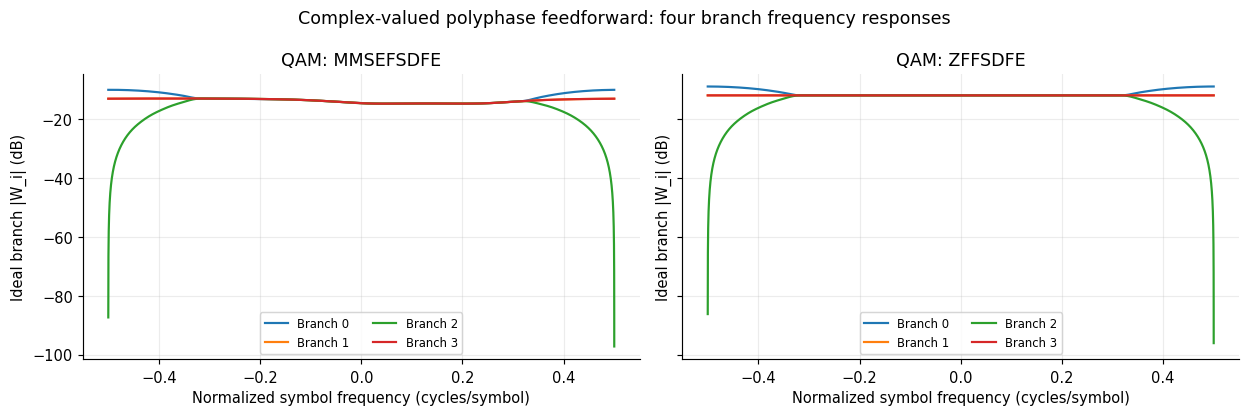

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True)
for ax, model, title in (
  (axes[0], qam_fs_mmse, "QAM: MMSEFSDFE"),
  (axes[1], qam_fs_zf, "QAM: ZFFSDFE"),
):
  freq = np.fft.fftshift(model._omega_bins) / (2 * np.pi)
  for branch in range(FS_OVERSAMPLING):
    magnitude = np.abs(np.fft.fftshift(model.w_branch_bins[branch]))
    ax.plot(freq, 20 * np.log10(np.maximum(magnitude, 1e-12)), label=f"Branch {branch}")
  ax.set(title=title, xlabel="Normalized symbol frequency (cycles/symbol)",
         ylabel="Ideal branch |W_i| (dB)")
  ax.legend(ncol=2, fontsize=8)
plt.suptitle("Complex-valued polyphase feedforward: four branch frequency responses")
plt.tight_layout()
plt.show()

## 12. Polyphase filter identities and error whitening

### 12.1 Why is the FS-DFE feedforward not the FS-LE feedforward?

For the same channel vector $[H_0,H_1,H_2,H_3]^T$, the ideal fractionally spaced **linear MMSE**
feedforward branch is

$$
W_{i,\rm MMSEFSE}(D)=\frac{H_i^\sharp(D)}{
\displaystyle\sum_{j=0}^{3}H_j^\sharp(D)H_j(D)
+4\frac{N_0/2}{\bar E_x}}.
$$

Multiplying by the minimum-phase MMSE feedback-related factor gives the FS-DFE feedforward:

$$
\begin{aligned}
G_{\rm FS}(D)W_{i,\rm MMSEFSE}(D)
&=\frac{G_{\rm FS}(D)H_i^\sharp(D)}
{4\|h\|_{\rm FS}^2\left(Q_{\rm FS}(D)+1/SNR_{\rm MFB}\right)}\\
&=\boxed{\frac{H_i^\sharp(D)}
{4\|h\|_{\rm FS}^2\gamma_{0,\rm FS}G_{\rm FS}^\sharp(D)}
=W_{i,\rm MMSEFSDFE}(D)}.
\end{aligned}
$$

Similarly, for the ideal ZF linear FSE,

$$
\boxed{P_{c,\rm FS}(D)W_{i,\rm ZFFSE}(D)
=W_{i,\rm ZFFSDFE}(D).}
$$

These equations express the same Cioffi identity
$W_{\rm DFE}(D)=B(D)W_{\rm LE}(D)$ **branch by branch**. They hold on the ideal
frequency grid; truncating each branch produces additional finite-length error.

In [30]:
fs_identity_rows = []
for label, models in (
  ("PAM", (pam_fs_mmse, pam_fs_zf)),
  ("QAM", (qam_fs_mmse, qam_fs_zf)),
):
  for model in models:
    polyphase_power = np.sum(np.abs(model.h_bins)**2, axis=0)
    regularizer = (FS_OVERSAMPLING * model.noise_var / model.symbol_energy
                   if model.criterion == "mmse" else 0.0)
    linear_fse_branches = np.conj(model.h_bins) / (polyphase_power[None, :] + regularizer)
    dfe_from_linear = model._g_bins[None, :] * linear_fse_branches
    frequency_error = float(np.max(abs(dfe_from_linear - model.w_branch_bins)))
    reconstruction_error = float(np.max(abs(
      model.polyphaseQBins() - polyphase_power / (FS_OVERSAMPLING * model.h_norm**2)
    )))
    fs_identity_rows.append({
      "Example": label,
      "Design": model.__class__.__name__,
      "max|W_DFE - B W_FSE|": frequency_error,
      "max|Q - H^H H / (4||h||^2)|": reconstruction_error,
    })
    assert frequency_error < 3e-11
    assert reconstruction_error < 1e-12

display(pd.DataFrame(fs_identity_rows))

,Example,Design,max|W_DFE - B W_FSE|,max|Q - H^H H / (4||h||^2)|
0,PAM,MMSEFSDFE,8.313942e-16,0.0
1,PAM,ZFFSDFE,4.035662e-14,0.0
2,QAM,MMSEFSDFE,8.391186e-16,0.0
3,QAM,ZFFSDFE,1.570092e-15,0.0


### 12.2 Whiteness of the optimal estimation error

With correct past decisions, the **biased** estimation error is

$$
E(D)=\left[B(D)-\sum_{i=0}^{3}W_i^{\rm FS}(D)H_i(D)\right]X(D)
-\sum_{i=0}^{3}W_i^{\rm FS}(D)N_i(D).
$$

Because the four high-rate noise phases are uncorrelated with one another and with symbols,

$$
\boxed{
\begin{aligned}
\bar R_{ee}(D)
={}&\bar E_x\left|B(D)-\sum_{i=0}^{3}W_i^{\rm FS}(D)H_i(D)\right|^2\\
&+4\frac{N_0}{2}\sum_{i=0}^{3}\left|W_i^{\rm FS}(D)\right|^2.
\end{aligned}
}
$$

The MMSE canonical factorization makes **total estimation-error PSD flat**:

$$
\boxed{\bar R_{ee}^{\rm MMSEFSDFE}(D)
=\frac{\bar E_x}{\gamma_{0,\rm FS}SNR_{\rm MFB}}.}
$$

The **filtered noise alone is generally colored** for MMSE, but is white for ZF:

$$
\boxed{\bar R_{n'n'}^{\rm ZFFSDFE}(D)
=\bar R_{ee}^{\rm ZFFSDFE}(D)
=\frac{\bar E_x}{\eta_{0,\rm FS}SNR_{\rm MFB}}.}
$$

The following code checks these identities independently using all four branch responses.

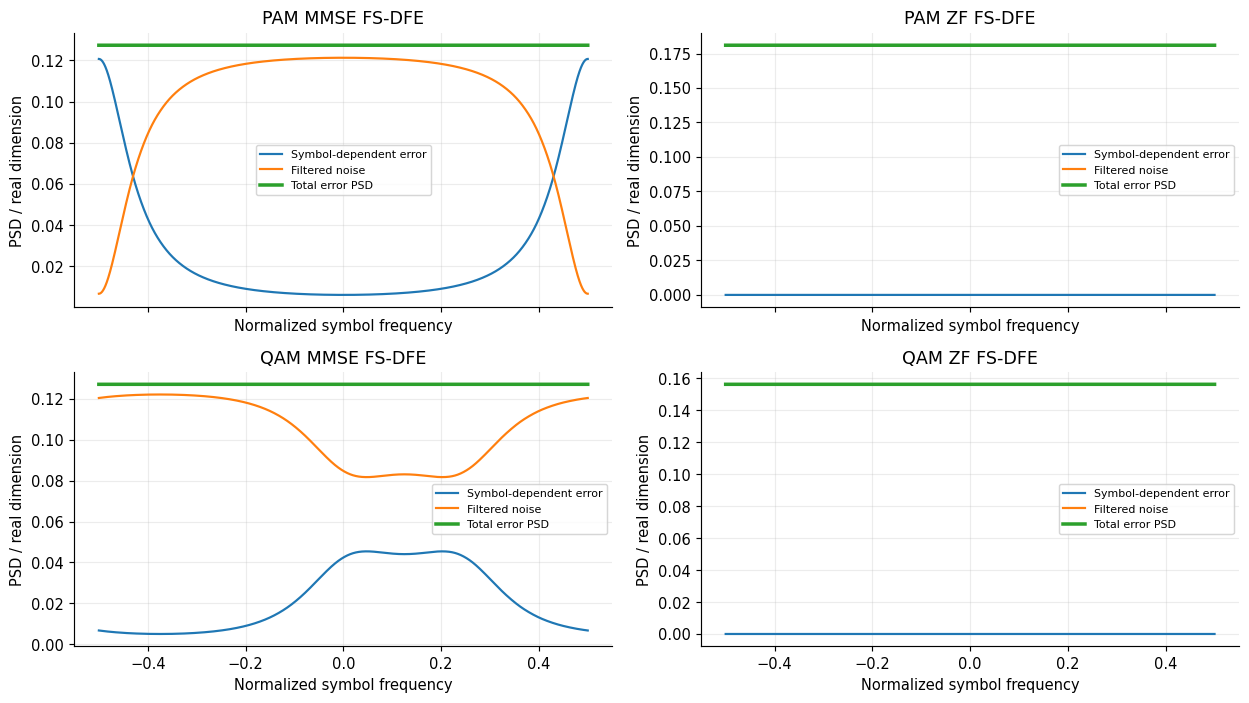

,Example,Receiver,Ideal biased error variance,Error-PSD max deviation,Filtered-noise PSD span
0,PAM,MMSEFSDFE,0.127378,9.159340e-16,1.146321e-01
1,PAM,ZFFSDFE,0.181004,2.070566e-14,2.914335e-14
2,QAM,MMSEFSDFE,0.127142,5.551115e-16,4.042036e-02
3,QAM,ZFFSDFE,0.156250,9.714451e-16,1.443290e-15


In [31]:
def fsIdealErrorSpectra(model):
  cascade = np.sum(model.w_branch_bins * model.h_bins, axis=0)
  symbol_dependent = SYMBOL_ENERGY_PER_REAL * np.abs(model._g_bins - cascade)**2
  filtered_noise = (FS_OVERSAMPLING * model.noise_var
                    * np.sum(np.abs(model.w_branch_bins)**2, axis=0))
  return symbol_dependent, filtered_noise, symbol_dependent + filtered_noise


fs_whitening_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True)
for row, (label, mmse, zf) in enumerate((
  ("PAM", pam_fs_mmse, pam_fs_zf),
  ("QAM", qam_fs_mmse, qam_fs_zf),
)):
  for column, model in enumerate((mmse, zf)):
    signal_psd, noise_psd, total_psd = fsIdealErrorSpectra(model)
    expected = model.idealMse(SYMBOL_ENERGY_PER_REAL)
    flatness = float(np.max(np.abs(total_psd - expected)))
    fs_whitening_rows.append({
      "Example": label,
      "Receiver": model.__class__.__name__,
      "Ideal biased error variance": expected,
      "Error-PSD max deviation": flatness,
      "Filtered-noise PSD span": float(np.ptp(noise_psd)),
    })
    assert flatness < 3e-11
    ax = axes[row, column]
    freq = np.fft.fftshift(model._omega_bins) / (2 * np.pi)
    ax.plot(freq, np.fft.fftshift(signal_psd), label="Symbol-dependent error")
    ax.plot(freq, np.fft.fftshift(noise_psd), label="Filtered noise")
    ax.plot(freq, np.fft.fftshift(total_psd), linewidth=2.4, label="Total error PSD")
    ax.set(title=f"{label} {model.criterion.upper()} FS-DFE", ylabel="PSD / real dimension")
    ax.legend(fontsize=7.5)
    ax.set_xlabel("Normalized symbol frequency")
    if model.criterion == "zf":
      assert np.ptp(noise_psd) < 3e-11

plt.tight_layout()
plt.show()
display(pd.DataFrame(fs_whitening_rows))

## 13. High-rate Monte Carlo and finite FIR effects

### 13.1 Physical high-rate receive samples, not matched-filter samples

The simulation inputs to `MMSEFSDFE.apply()` and `ZFFSDFE.apply()` are the **four-times-sampled
receive arrays**. No matched-filter output is substituted for these inputs:

$$
\boxed{
\begin{aligned}
r[n]&=\sum_k g[n-4k]x[k]+v[n],\\
\operatorname{Var}(\Re v[n])&=\operatorname{Var}(\Im v[n])
=4\frac{N_0}{2}\quad\text{(QAM)},\\
\operatorname{Var}(v[n])&=4\frac{N_0}{2}\quad\text{(real PAM)}.
\end{aligned}}
$$

Noise is white **before** polyphase analysis. The receiver computes each branch's FIR contribution
and then runs the **same symbol-rate feedback algorithm** as the symbol-spaced DFE.

- **Correct-feedback run:** supplies true past symbols to isolate the equalizer design error.
- **Decision-directed run:** supplies true past symbols for 384 decisions, then feeds back slicer
  decisions. The coefficients are fixed; no adaptive LMS/RLS update occurs.
- **Bias test:** for the same feedback decisions,
  $Z'_U(D)=Z'(D)/\alpha_{\rm FS}$ and the feedback polynomial is
  $G_{U,\rm FS}(D)=1+[G_{\rm FS}(D)-1]/\alpha_{\rm FS}$.

Since feedforward FIRs have noncausal symbol lags, a guard of 384 symbols is discarded at each
record boundary. This is an *offline* model of finite lookahead, not a hardware scheduling design.

In [32]:
def simulateFsReceiverPair(channel, constellation, g_index, g, mmse, zf, rng, complex_channel):
  symbols = randomSymbols(rng, constellation, N_SYMBOLS)
  received = sampleChannelOutput(symbols, g_index, g, FS_OVERSAMPLING)
  unit_noise = rng.standard_normal(len(received))
  if complex_channel:
    unit_noise = unit_noise + 1j * rng.standard_normal(len(received))
  received = received + np.sqrt(FS_OVERSAMPLING * mmse.noise_var) * unit_noise

  rows = []
  result_by_method = {}
  for model in (mmse, zf):
    correct = model.apply(
      received, n_symbols=len(symbols), known_symbols=symbols,
      ideal_feedback=True, unbiased=True,
    )
    directed = model.apply(
      received, n_symbols=len(symbols), known_symbols=symbols,
      training_samples=GUARD, unbiased=True,
    )
    # Same true feedback symbols: biased-summing and unbiased-summing are algebraically equivalent.
    biased = model.apply(
      received, n_symbols=len(symbols), known_symbols=symbols,
      ideal_feedback=True, unbiased=False,
    )
    start, stop = GUARD, N_SYMBOLS - GUARD
    valid = slice(start, stop)
    dimension_count = 2 if complex_channel else 1
    mse_correct = float(np.mean(np.abs(symbols[valid] - correct.decision_input[valid])**2)
                        / dimension_count)
    mse_directed = float(np.mean(np.abs(symbols[valid] - directed.decision_input[valid])**2)
                         / dimension_count)
    max_bias_mismatch = float(np.max(np.abs(
      correct.decision_input[valid] - biased.decision_input[valid] / model.alpha()
    )))
    assert max_bias_mismatch < 2e-10
    assert np.array_equal(correct.decisions, biased.decisions)
    predicted = 1.0 / model.unbiasedSnr()
    assert abs(predicted - mse_correct) / predicted < 0.10
    rows.append({
      "Receiver": model.__class__.__name__,
      "Theory MSE / real": predicted,
      "Correct-feedback MSE": mse_correct,
      "Decision-directed MSE": mse_directed,
      "Correct-feedback SER": float(np.mean(correct.decisions[valid] != symbols[valid])),
      "Decision-directed SER": float(np.mean(directed.decisions[valid] != symbols[valid])),
      "Bias scaling max error": max_bias_mismatch,
    })
    result_by_method[model.criterion] = (correct, directed, biased)
  return rows, result_by_method


fs_rng = np.random.default_rng(RNG_SEED + 17)
fs_sim_rows = []
fs_sim_outputs = {}
for name, channel, constellation, g_index, g, mmse, zf, complex_channel in (
  ("PAM", pam_h, pam_constellation, pam_g_index, pam_g, pam_fs_mmse, pam_fs_zf, False),
  ("QAM", qam_h, qam_constellation, qam_g_index, qam_g, qam_fs_mmse, qam_fs_zf, True),
):
  rows, outputs = simulateFsReceiverPair(
    channel, constellation, g_index, g, mmse, zf, fs_rng, complex_channel,
  )
  for row in rows:
    fs_sim_rows.append({"Example": name, **row})
  fs_sim_outputs[name] = outputs

fs_sim_table = pd.DataFrame(fs_sim_rows)
display(fs_sim_table.round(7))
print(f"FS-DFE: {N_SYMBOLS} high-rate symbol intervals per example; "
      f"{FS_OVERSAMPLING * N_SYMBOLS} ADC samples each")

,Example,Receiver,Theory MSE / real,Correct-feedback MSE,Decision-directed MSE,Correct-feedback SER,Decision-directed SER,Bias scaling max error
0,PAM,MMSEFSDFE,0.145972,0.146735,0.165866,0.004391,0.010158,0.0
1,PAM,ZFFSDFE,0.181004,0.181869,0.234628,0.009814,0.016658,0.0
2,QAM,MMSEFSDFE,0.145662,0.145366,0.156932,0.008781,0.015539,0.0
3,QAM,ZFFSDFE,0.156250,0.156243,0.172806,0.010933,0.018294,0.0


FS-DFE: 24000 high-rate symbol intervals per example; 96000 ADC samples each


### 13.2 Independent finite-FIR MSE prediction

The previous **ideal** SNR formulas assume infinite-length FF and full canonical feedback.
To measure the **actually implemented** FIR, first form the polyphase cascade

$$
\begin{aligned}
C_{\rm FIR}(D)&=\sum_{i=0}^{3}W_{i,\rm FIR}(D)H_i(D),\\
R_{\rm FIR}(D)&=C_{\rm FIR}(D)+1-B_{\rm FIR}(D).
\end{aligned}
$$

The unbiased effective symbol response becomes
$R_{\rm FIR}(D)/\alpha_{\rm FS}$, not necessarily the identity polynomial.
Under independent symbols, the corresponding mean-square error (per real dimension) is

$$
\boxed{
\begin{aligned}
\sigma_{\rm finite,U}^2
={}&\bar E_x\sum_m\left|\delta[m]
-\frac{r_{\rm FIR}[m]}{\alpha_{\rm FS}}\right|^2\\
&+\frac{4(N_0/2)}{\alpha_{\rm FS}^2}
\sum_{i=0}^{3}\sum_m|w_{i,\rm FIR}[m]|^2.
\end{aligned}
}
$$

This independent energy-domain prediction separately identifies (i) finite FIR symbol-response
error and (ii) receiver noise. It is especially important for *ZFFSDFE*: ideal ZF cancellation
holds for the infinite response, while a finite FF may leave residual ISI.

In [33]:
def fsFiniteUnbiasedMse(model):
  cascade_index, cascade = model.finiteCascade()
  effective = cascade.copy()
  # Correct-feedback path: 1-B(D) is strictly causal, and uses textbook-order taps.
  for lag, coef in enumerate(model.feedback_polynomial[1:], start=1):
    location = np.flatnonzero(cascade_index == lag)
    if len(location) != 1:
      raise AssertionError("finite cascade omits a required feedback lag")
    effective[location[0]] -= coef
  desired = np.zeros(len(effective), dtype=np.complex128)
  desired[np.flatnonzero(cascade_index == 0)[0]] = 1.0
  symbol_error = float(model.symbol_energy * np.sum(abs(desired - effective / model.alpha())**2))
  noise_error = float(FS_OVERSAMPLING * model.noise_var
                      * np.sum(abs(model.w_branch)**2) / model.alpha()**2)
  return symbol_error, noise_error, symbol_error + noise_error


fs_finite_rows = []
for name, mmse, zf in (
  ("PAM", pam_fs_mmse, pam_fs_zf),
  ("QAM", qam_fs_mmse, qam_fs_zf),
):
  for model in (mmse, zf):
    symbol_mse, noise_mse, finite_mse = fsFiniteUnbiasedMse(model)
    monte_carlo = fs_sim_table.loc[
      (fs_sim_table["Example"] == name) & (fs_sim_table["Receiver"] == model.__class__.__name__),
      "Correct-feedback MSE",
    ].iloc[0]
    fs_finite_rows.append({
      "Example": name,
      "Receiver": model.__class__.__name__,
      "Ideal infinite MSE": 1 / model.unbiasedSnr(),
      "Finite symbol error": symbol_mse,
      "Finite noise": noise_mse,
      "Predicted finite MSE": finite_mse,
      "Monte Carlo finite MSE": monte_carlo,
    })
    assert abs(monte_carlo - finite_mse) / finite_mse < 0.10

fs_finite_table = pd.DataFrame(fs_finite_rows)
display(fs_finite_table.round(8))

,Example,Receiver,Ideal infinite MSE,Finite symbol error,Finite noise,Predicted finite MSE,Monte Carlo finite MSE
0,PAM,MMSEFSDFE,0.145972,1.427405e-02,0.131698,0.145972,0.146736
1,PAM,ZFFSDFE,0.181004,3.000000e-08,0.181004,0.181004,0.181870
2,QAM,MMSEFSDFE,0.145662,8.161890e-03,0.137500,0.145662,0.145365
3,QAM,ZFFSDFE,0.156250,8.000000e-08,0.156250,0.156250,0.156243


## 14. Unified results and reproducibility

### 14.1 Side-by-side symbol-spaced and four-branch FS-DFE

For ideal bandlimited/Nyquist sampling, the matched filter yields sufficient statistics. Hence
fractional spacing itself does not guarantee a higher ideal SNR relative to a correctly implemented,
ideal symbol-spaced matched-filter DFE. It changes the **realization**: sampling phase flexibility,
anti-alias front end, and four symbol-rate feedforward branches.

For finite pulse length, the normalized spectra differ slightly, so the computed values are close
but not **numerically identical**. This difference is explicitly measured rather than hidden.

The four receiver designs share the same sequence of operations:

1. Compute high-rate pulse, four polyphase channel branches, and $Q_{\rm FS}(D)$.
2. Apply **MMSE** regularization $1/SNR_{\rm MFB}$ or **ZF** without regularization.
3. Calculate the minimum-phase canonical factor and its scale.
4. Form four feedforward responses $W_i^{\rm FS}(D)$.
5. Apply symbol-rate feedback $1-G_{\rm FS}(D)$ or $1-P_{c,\rm FS}(D)$.
6. For MMSE unbiased detection apply $1/\alpha_{\rm FS}$, use $1-G_{U,\rm FS}(D)$, and slice the original constellation.
7. Compare theoretical SNR with the actual finite FIR and Monte Carlo MSEs.

**Keep the ideal-versus-finite distinction:** the FS equations are infinite-length identities;
the 161-tap branches and textbook-order feedback are explicitly finite approximations.

,Example,Method,γ₀ / η₀ (FS),γ₀ / η₀ (SS),α (FS),SNR_FS (dB),SNR_SS (dB),Difference (dB)
0,PAM,MMSEFSDFE,0.785063,0.785063,0.872622,8.357306,8.357308,-0.000002
1,PAM,ZFFSDFE,0.552473,0.552486,1.000000,7.423115,7.423214,-0.000100
2,QAM,MMSEFSDFE,0.786521,0.786520,0.872858,8.366536,8.366534,0.000002
3,QAM,ZFFSDFE,0.640000,0.640000,1.000000,8.061802,8.061800,0.000002


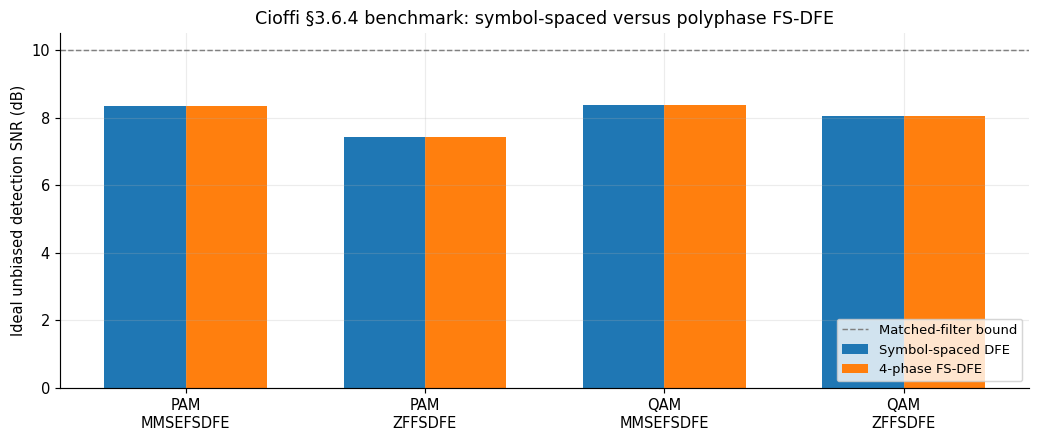

In [34]:
final_fs_table = pd.DataFrame([
  fsSummary("PAM", pam_fs_mmse, pam_mmse),
  fsSummary("PAM", pam_fs_zf, pam_zf),
  fsSummary("QAM", qam_fs_mmse, qam_mmse),
  fsSummary("QAM", qam_fs_zf, qam_zf),
])
display(final_fs_table.round(7))

fig, ax = plt.subplots(figsize=(10, 4.3))
positions = np.arange(len(final_fs_table))
bar_width = 0.34
ax.bar(positions - bar_width / 2, final_fs_table["SNR_SS (dB)"], bar_width, label="Symbol-spaced DFE")
ax.bar(positions + bar_width / 2, final_fs_table["SNR_FS (dB)"], bar_width, label="4-phase FS-DFE")
ax.axhline(positiveDb(SNR_MFB), linestyle="--", color="gray", linewidth=1, label="Matched-filter bound")
ax.set_xticks(positions, [f"{row.Example}\n{row.Method}" for row in final_fs_table.itertuples()])
ax.set_ylabel("Ideal unbiased detection SNR (dB)")
ax.set_title("Cioffi §3.6.4 benchmark: symbol-spaced versus polyphase FS-DFE")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

### 14.2 Reproduction checks and limitations

The notebook verifies all of the following in code:

- The four-branch polyphase autocorrelation is normalized to $q_{\rm FS}[0]=1$ and preserves
  complex Hermitian symmetry for QAM.
- The FFT-grid canonical spectral factorization reconstructs the regularized (MMSE) and
  unregularized (ZF) four-branch spectrum.
- The feedforward identity $W_{i,\rm FSDFE}=B_{\rm FS}W_{i,\rm FSE}$ holds for **every phase**.
- MMSE total estimation error and ZF filtered noise have the correct constant theoretical PSD.
- Biased and unbiased MMSE decision-input structures are equivalent when they use the same
  previous decisions.
- High-rate noisy data processed by the 4-branch FF and symbol-rate feedback reproduces the
  predicted correct-decision MSE within Monte Carlo tolerance.
- The **actual finite FIR** MSE follows the independently computed signal-response and
  noise-power decomposition.
- PAM/QAM analytical SNRs are close to the original §3.6.4 symbol-spaced results.

**Limitations:** finite RRC support modifies the exact textbook $Q(D)$ slightly;
`n_fb=1` (PAM) and `n_fb=2` (QAM) deliberately truncate the longer pulse's tiny feedback tail;
noncausal FF requires buffering/lookahead; decision-directed error propagation remains;
no jointly optimal finite-length design (Chapter 3.7), adaptive channel estimation, timing
recovery, quantized RTL, or hardware latency scheduling is claimed.

In [35]:
assert len(final_fs_table) == 4
assert all(abs(row["Difference (dB)"]) < 0.005 for _, row in final_fs_table.iterrows())
assert all(row["Error-PSD max deviation"] < 3e-11 for row in fs_whitening_rows)
assert all(row["max|W_DFE - B W_FSE|"] < 3e-11 for row in fs_identity_rows)
assert all(row["Bias scaling max error"] < 2e-10 for row in fs_sim_rows)

print("POLYPHASE FS-DFE REPRODUCTION PASSED")
print(f"4 polyphase branches; T_s=T/{FS_OVERSAMPLING}; {FS_FF_TAPS_PER_BRANCH} FIR taps per branch")
for _, row in final_fs_table.iterrows():
  print(f"  {row['Example']} {row['Method']}: "
        f"FS={row['SNR_FS (dB)']:.6f} dB, "
        f"symbol-spaced={row['SNR_SS (dB)']:.6f} dB, "
        f"difference={row['Difference (dB)']:+.6f} dB")
print("All spectral, polyphase, feedback, whitening, Monte Carlo and finite-FIR checks passed.")

POLYPHASE FS-DFE REPRODUCTION PASSED
4 polyphase branches; T_s=T/4; 161 FIR taps per branch
  PAM MMSEFSDFE: FS=8.357306 dB, symbol-spaced=8.357308 dB, difference=-0.000002 dB
  PAM ZFFSDFE: FS=7.423115 dB, symbol-spaced=7.423214 dB, difference=-0.000100 dB
  QAM MMSEFSDFE: FS=8.366536 dB, symbol-spaced=8.366534 dB, difference=+0.000002 dB
  QAM ZFFSDFE: FS=8.061802 dB, symbol-spaced=8.061800 dB, difference=+0.000002 dB
All spectral, polyphase, feedback, whitening, Monte Carlo and finite-FIR checks passed.
